# Project 1: Camera Characterization Pipeline & Verification Notebook
## Foundations of Computer Vision — EE 513
Executes core camera characterization stages, running real image analysis alongside synthetic simulation benchmarks.

### Section 1: Environment Setup & Configuration Loading

In [2]:
import os
import sys
import yaml
import glob
import numpy as np
import rawpy
import cv2
import matplotlib.pyplot as plt
import importlib
import colour
from pathlib import Path

# Add src directory to sys.path
REPO_ROOT = Path(".").resolve()
src_path = REPO_ROOT / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Import camera_toolkit package modules
from camera_toolkit import utils, geometry, resolution, noise, color, dynamics, plots, simulator, report_generator

# Environment verification
utils.verify_environment()

# Load configuration from config.yaml
config_path = REPO_ROOT / "config.yaml"
if config_path.exists():
    with open(config_path, "r") as f:
        config = yaml.safe_load(f)
else:
    config = {
        "project": {"camera_name": "Google Pixel 9", "output_dir": "./outputs"},
        "geometry": {"input_dir": "./images/checkerboard/all", "file_extension": ".dng", "focal_35mm_fallback": 25.0, "checkerboard": {"rows": 6, "cols": 9, "square_size_mm": 19.0}},
        "resolution": {"input_dir": "./images/slanted_edge", "file_extension": ".dng"},
        "noise": {"flat_dir": "./images/flat_fields", "dark_dir": "./images/dark_frames", "file_extension": ".dng"},
        "color": {"input_dir": "./images/color_checker", "file_extension": ".dng"}
    }

output_dir = config["project"].get("output_dir", "./outputs")
os.makedirs(output_dir, exist_ok=True)
print(f"Successfully initialized configuration. Output directory: {output_dir}")

--- Environment Validation ---
Python     : 3.12.15
rawpy      : 0.27.1
colour     : 0.4.7
numpy      : 2.5.3
cv2        : 5.0.0
yaml       : 6.0.3
matplotlib : 3.11.2
tifffile   : 2026.9.20
Environment Validation Passed Successfully.

Successfully initialized configuration. Output directory: ./outputs


In [3]:
file_path = r"C:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\images\checkerboard\all\IMG_20261108_110258.dng"

with rawpy.imread(file_path) as raw:
    # 1. Active sensor dimensions (Unrotated: height, width)
    # Best for camera characterization and raw pixel analysis
    height, width = raw.raw_image_visible.shape
    print(f"Sensor Dimensions -> Width: {width}, Height: {height}")

    # 2. Fast metadata check without loading the full image into memory
    print(f"Metadata Sizes -> Width: {raw.sizes.width}, Height: {raw.sizes.height}")


Sensor Dimensions -> Width: 4080, Height: 3072
Metadata Sizes -> Width: 4080, Height: 3072


### Section 2: Camera Lens Profile Audit

In [ ]:
geom_cfg = config.get("geometry", {})
target_dir = geom_cfg.get("input_dir", "./images/checkerboard/all")
dng_files = utils.get_dng_files(target_dir)

if dng_files:
    meta = utils.extract_dng_metadata(dng_files[0], config=config) 
    camera_make = meta["make"]
    camera_model = meta["model"]
    focal_length_mm = meta["focal_length_mm"]
    f_stop = meta["f_number"]
    focal_35mm = meta["focal_35mm"]
    raw_width = meta["image_width"]
    raw_height = meta["image_length"]
    cfa_pattern = meta["cfa_pattern"]
    img_black_level = meta["black_level"]
    img_black_level_std = meta["black_level_std"]
    white_level = meta["white_level"]

    print("Camera Lens Profile Audit:")
    print(f"  Camera Make:     {camera_make}")
    print(f"  Device Model:    {camera_model}")
    print(f"  Focal Length:    {focal_length_mm} mm")
    print(f"  F-stop:          f/{f_stop}")
    print(f"  35mm Equivalent: {focal_35mm} mm")
    print(f"  Sensor Shape:    ({raw_width}, {raw_height}) (Width x Height)")
    print(f"  CFA Pattern:     {cfa_pattern}")
    print(f"  Black Level:     {img_black_level:.2f} +/- {img_black_level_std:.2f} DN")
    print(f"  White Level:     {white_level} DN")
else:
    print("No DNG captures found on local disk. Loading baseline default profile...")
    camera_make, camera_model = "Google", "Google Pixel 9"
    focal_length_mm, f_stop, focal_35mm = 6.9, 1.68, 25.0
    raw_width, raw_height = 4080, 3072
    cfa_pattern = "GBRG"
    black_level, white_level = 0.0, 0.0
    print("Default Camera Profile Initialized.")

Camera Lens Profile Audit:
  Camera Make:     Google
  Device Model:    Pixel 9
  Focal Length:    6.9 mm
  F-stop:          f/1.68
  35mm Equivalent: 25.0 mm
  Sensor Shape:    (4080, 3072) (Width x Height)
  CFA Pattern:     GBRG
  Black Level:     63.95 +/- 0.01 DN
  White Level:     1023.0 DN


In [5]:
# Scan ISO 22 noise captures (flat fields + dark frames) to extract EXIF BlackLevel [mean, std]
flat_paths = utils.get_dng_files(config["noise"]["flat_dir"])
dark_paths = utils.get_dng_files(config["noise"]["dark_dir"])
all_noise_paths = flat_paths + dark_paths

bl_mean, bl_std, bl_n_size = noise.compute_exif_black_level(all_noise_paths)
black_level = bl_mean
black_level_std = bl_std
black_level_samples = bl_n_size

print(f"Global ISO 22 EXIF Black Level (n={bl_n_size}): {black_level:.4f} ± {black_level_std:.4f} DN")


Global ISO 22 EXIF Black Level (n=54): 63.9841 ± 0.0138 DN


### Section 3: Cross Directory Hardware Compatibility & Exposure Audit

In [6]:
res_cfg = config["resolution"]
res_base = res_cfg["input_dir"]
res_ext = res_cfg.get("file_extension", ".dng")

pipeline_directories = {
    "Checkboard Captures": (config["geometry"]["input_dir"], config["geometry"].get("file_extension", ".dng")),
}

# Add each slanted-edge region subfolder dynamically
for region in res_cfg.get("regions", []):
    label = f"Slanted Edge ({region})"
    region_path = os.path.join(res_base, region)
    pipeline_directories[label] = (region_path, res_ext)

pipeline_directories.update({
    "Noise: Flat Fields": (config["noise"]["flat_dir"], config["noise"].get("file_extension", ".dng")),
    "Noise: Dark Frames": (config["noise"]["dark_dir"], config["noise"].get("file_extension", ".dng")),
    "Color Chart Captures": (config["color"]["input_dir"], config["color"].get("file_extension", ".dng")),
})

global_baseline, exposure_summary = utils.run_cross_directory_audit(pipeline_directories, config=config)

=== Starting Global Multi-Directory Pipeline Audit ===
Auditing 68 DNG files in [Checkboard Captures]...
Auditing 5 DNG files in [Slanted Edge (center)]...
Auditing 5 DNG files in [Slanted Edge (top_left)]...
Auditing 5 DNG files in [Slanted Edge (top_right)]...
Auditing 5 DNG files in [Slanted Edge (bottom_left)]...
Auditing 5 DNG files in [Slanted Edge (bottom_right)]...
Auditing 24 DNG files in [Noise: Flat Fields]...
Auditing 30 DNG files in [Noise: Dark Frames]...
Auditing 16 DNG files in [Color Chart Captures]...

GLOBAL DATASET AUDIT METRICS MATCHED
All discovered assets confirmed as authentic Un-Demosaiced Bayer Matrices.
Unified Shared Hardware Footprint Verified:
 • Device Model:    Pixel 9
 • Focal Length:    6.9 mm
 • F-stop:          f/1.68
 • 35mm Equivalent: 25.0 mm
 • Sensor Bounds:   (4080, 3072) (Width x Height)

=== Exposure & ISO Audit ===
Stage Directory [Checkboard Captures] (68 files total):
   ↳ Unique ISO brackets:      [400]
   ↳ Unique Shutter Speeds:    ['1/

### Section 4: Geometry
#### 4.1 Synthetic Simulation Benchmarking

In [7]:
print("================================================================")
print("GEOMETRY - SYNTHETIC SIMULATION BENCHMARK (n=15 views)")
print("================================================================")

syn_obj_list, syn_img_list, syn_shape, K_true, dist_true = simulator.generate_synthetic_checkerboard_session(
    n_views=15, image_shape=(raw_width, raw_height)
)

sim_payload = geometry.run_extended_calibration(syn_obj_list, syn_img_list, syn_shape)
rms_sim = sim_payload["rms_reprojection_error"][0]
fx_sim, sfx_sim = sim_payload["focal_length_x"]
fy_sim, sfy_sim = sim_payload["focal_length_y"]
cx_sim, scx_sim = sim_payload["principal_point_x"]
cy_sim, scy_sim = sim_payload["principal_point_y"]

print(f"Ground Truth f_x:           {K_true[0,0]:.2f} px")
print(f"Recovered f_x:              {fx_sim:.2f} +/- {sfx_sim:.2f} px (Error: {abs(fx_sim - K_true[0,0])/K_true[0,0]*100:.3f}%)")
print(f"Ground Truth f_y:           {K_true[1,1]:.2f} px")
print(f"Recovered f_y:              {fy_sim:.2f} +/- {sfy_sim:.2f} px (Error: {abs(fy_sim - K_true[1,1])/K_true[1,1]*100:.3f}%)")
print(f"Principal Point (cx, cy):   ({cx_sim:.2f}, {cy_sim:.2f}) px")
print(f"Simulation Reprojection RMS: {rms_sim:.4f} px")

GEOMETRY - SYNTHETIC SIMULATION BENCHMARK (n=15 views)
Ground Truth f_x:           3055.61 px
Recovered f_x:              3055.70 +/- 11.28 px (Error: 0.003%)
Ground Truth f_y:           3055.61 px
Recovered f_y:              3055.63 +/- 11.29 px (Error: 0.001%)
Principal Point (cx, cy):   (2017.65, 1566.73) px
Simulation Reprojection RMS: 0.3463 px


#### 4.2 Real DNG Geometric Calibration & Lens Distortion

[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\outputs\figures\checkerboard_0_5m_contact_sheet.png


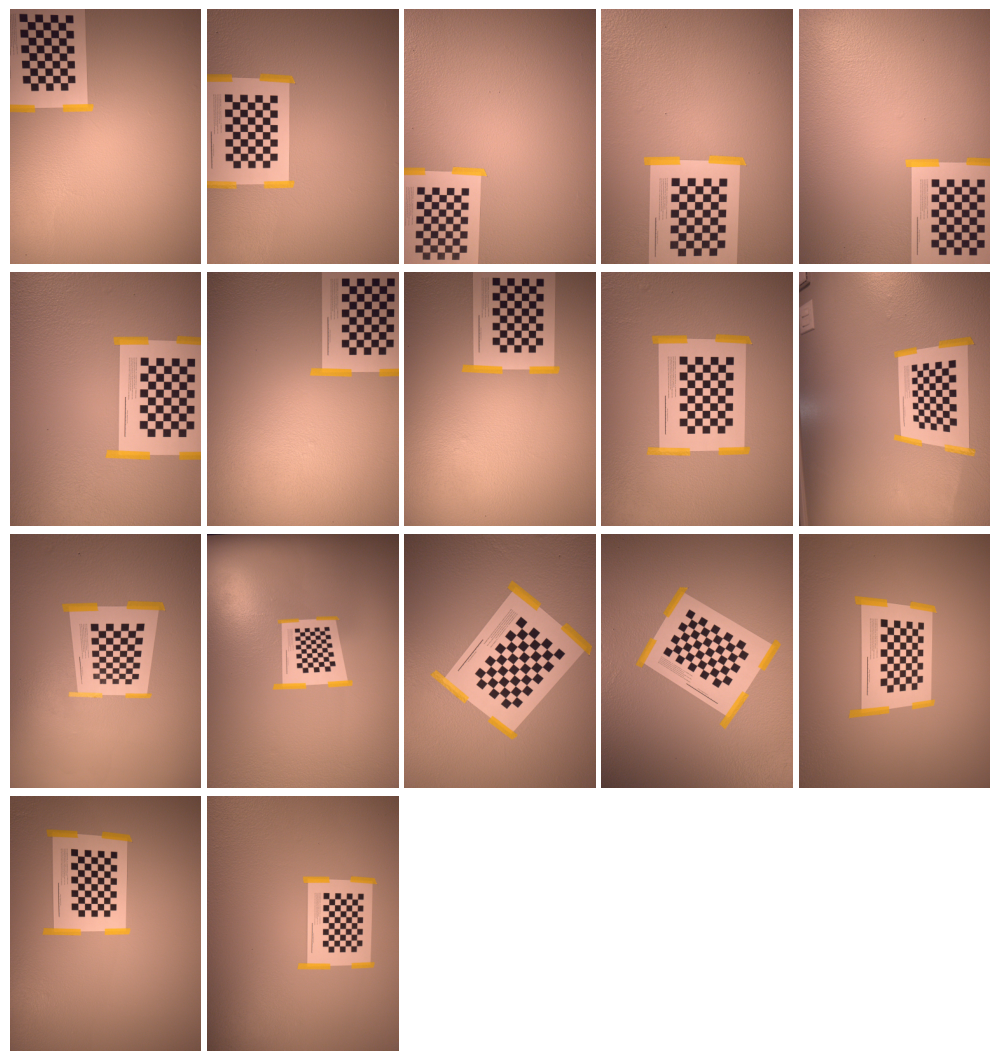

'c:\\Users\\nmmon\\Desktop\\EE513\\Project1\\camera_characterization\\outputs\\figures\\checkerboard_0_5m_contact_sheet.png'

In [8]:
# ---------------------------------------------------------
#  Contact Sheet of Captured Views - Example of 0.5m
# ---------------------------------------------------------
example_dir = "./images/checkerboard/0_5m"
plots.plot_directory_contact_sheet(
    input_dir=example_dir,
    cols=5,
    output_dir=output_dir,
    filename="checkerboard_0_5m_contact_sheet.png",
)

In [9]:
# ---------------------------------------------------------
# 1. Checkerboard Target Setup
# ---------------------------------------------------------
# Read checkerboard grid dimensions (inner corners) and square physical size from config
rows, cols = geom_cfg.get("checkerboard", {}).get("rows", 6), geom_cfg.get("checkerboard", {}).get("cols", 9)
sq_size = geom_cfg.get("checkerboard", {}).get("square_size_mm", 19.0)

# Generate ideal 3D planar world coordinates (Z = 0) for the checkerboard corners
ideal_obj_points = geometry.generate_object_points(rows=rows, cols=cols, square_size_mm=sq_size)

# ---------------------------------------------------------
# 2. Sub-Pixel Corner Detection Across Raw DNG Captures
# ---------------------------------------------------------
all_obj_real, all_img_real = [], []
img_shape_real = (raw_width, raw_height)

if os.path.exists(target_dir):
    image_paths = utils.get_dng_files(target_dir)
    for p in image_paths:
        g = utils.load_dng_for_geometry(p)
        if g is not None:
            img_shape_real = (g.shape[1], g.shape[0])
            success, corners = geometry.detect_checkerboard_corners(g, rows=rows, cols=cols)
            if success:
                all_obj_real.append(ideal_obj_points)
                all_img_real.append(corners)

passed_count = len(all_img_real)
total_scanned = len(image_paths) if os.path.exists(target_dir) and image_paths else 0
print(f"Checkerboard Corner Detection: {passed_count} / {total_scanned} captures passed")

# ---------------------------------------------------------------
# 3. Extended Zhang Camera Calibration (Intrinsics & Distortion)
# ---------------------------------------------------------------
# Solve for camera matrix K, 5 distortion coefficients, extrinsics, and parameter uncertainties
if passed_count >= 3:
    calib_payload = geometry.run_extended_calibration(all_obj_real, all_img_real, img_shape_real)
else:
    print("Real DNG captures not found in folder. Utilizing simulation payload for calibration reporting.")
    calib_payload = sim_payload
    all_img_real = syn_img_list
    all_obj_real = syn_obj_list

# Unpack calibrated parameters and their 1-sigma uncertainties
rms = calib_payload["rms_reprojection_error"][0]
fx, sfx = calib_payload["focal_length_x"]
fy, sfy = calib_payload["focal_length_y"]
cx, scx = calib_payload["principal_point_x"]
cy, scy = calib_payload["principal_point_y"]
k1, sk1 = calib_payload["radial_distortion_k1"]
k2, sk2 = calib_payload["radial_distortion_k2"]
p1, sp1 = calib_payload["tangential_distortion_p1"]
p2, sp2 = calib_payload["tangential_distortion_p2"]
k3, sk3 = calib_payload["radial_distortion_k3"]

print("=========================================================")
print("STAGE 1: REAL GEOMETRIC CALIBRATION STATISTICS")
print("=========================================================")
print(f"RMS reprojection error   {rms:.4f} px\n")
print(f"f_x  {fx:9.2f}  +/- SFX: {sfx:.2f} px")
print(f"f_y  {fy:9.2f}  +/- SFY: {sfy:.2f} px")
print(f"c_x  {cx:9.2f}  +/- SCX: {scx:.2f} px")
print(f"c_y  {cy:9.2f}  +/- SCY: {scy:.2f} px")
print("\n--- Distortion Coefficients ---")
print(f"k_1  {k1:9.4f}  +/- {sk1:.4f}")
print(f"k_2  {k2:9.4f}  +/- {sk2:.4f}")
print(f"k_3  {k3:9.4f}  +/- {sk3:.4f}")
print(f"p_1  {p1:9.4f}  +/- {sp1:.4f}")
print(f"p_2  {p2:9.4f}  +/- {sp2:.4f}")

Checkerboard Corner Detection: 68 / 68 captures passed
STAGE 1: REAL GEOMETRIC CALIBRATION STATISTICS
RMS reprojection error   0.9595 px

f_x    3048.03  +/- SFX: 6.54 px
f_y    3043.67  +/- SFY: 6.52 px
c_x    1509.05  +/- SCX: 2.81 px
c_y    2065.80  +/- SCY: 2.68 px

--- Distortion Coefficients ---
k_1     0.0418  +/- 0.0017
k_2    -0.1081  +/- 0.0056
k_3     0.1003  +/- 0.0062
p_1     0.0012  +/- 0.0002
p_2     0.0012  +/- 0.0002



Straightness Deviation BEFORE Undistort: 0.1994 px
Straightness Deviation AFTER Undistort:  0.1323 px
[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\images\outputs\figures\rectified_comparison.png


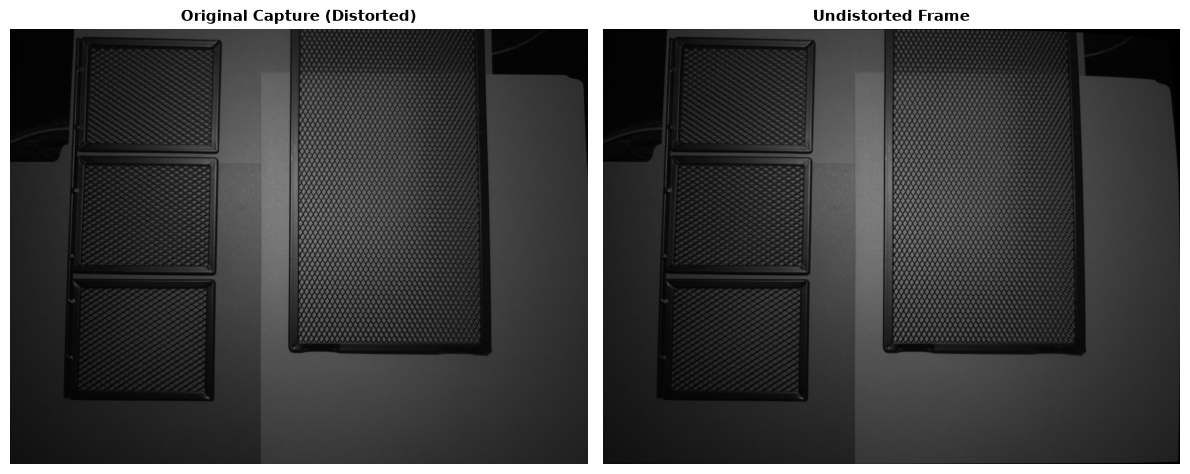

[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\outputs\figures\distortion_check.png


In [10]:
# ---------------------------------------------------------
# 4. Distortion Rectification & Edge Straightness Validation
# ---------------------------------------------------------
# Reconstruct K matrix and distortion vector to quantify boundary line straightness improvement
K_mat = utils.reconstruct_k_matrix(calib_payload)
dist_vec = utils.reconstruct_dist_vector(calib_payload)
dev_before, dev_after = geometry.evaluate_straightness_improvement(all_img_real, K_mat, dist_vec)
print(f"\nStraightness Deviation BEFORE Undistort: {dev_before:.4f} px")
print(f"Straightness Deviation AFTER Undistort:  {dev_after:.4f} px")
importlib.reload(plots)
# Generate and save a side-by-side raw vs. undistorted image comparison
sample_p = r"C:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\images\gallery\IMG_20261011_113927.dng"#image_paths[0]
sample_img = utils.load_dng_for_geometry(sample_p)
if sample_img is not None:
        sample_bgr = cv2.cvtColor(sample_img, cv2.COLOR_GRAY2BGR) if len(sample_img.shape) == 2 else sample_img.copy()
        rectified_bgr = geometry.rectify_frame(sample_bgr, K_mat, dist_vec, alpha=1.0)
        plots.plot_rectified_comparison(sample_bgr, rectified_bgr)
        plots.save_distortion_comparison(sample_bgr, rectified_bgr, output_dir=output_dir)

In [11]:
# ---------------------------------------------------------
# 5. Effective Pixel Pitch Cross-Validation (Two Independent Routes)
# ---------------------------------------------------------
# Combine fx and fy into a weighted mean focal length in pixels
mean_focal_length_px = (fx + fy) / 2.0
mean_focal_length_uncertainty_px = np.sqrt(sfx**2 + sfy**2) / 2.0

# Compare pixel pitch from calibrated focal length + EXIF f_mm (Method 1) vs. 35mm crop factor (Method 2)
pitch_metrics = geometry.calculate_pixel_pitch_metrics(mean_focal_length_px, focal_length_mm, focal_35mm, img_shape_real)
p_um = pitch_metrics["pixel_pitch_method1_um"]

print(f"\nPhysical Focal Length: {focal_length_mm} mm | 35mm Equivalent: {focal_35mm} mm")
print(f"Mean Focal Length:     {mean_focal_length_px:.2f} +/- {mean_focal_length_uncertainty_px:.2f} px")
print(f"Standard Deviation:    {mean_focal_length_uncertainty_px:.2f} px")
print(f"Method 1 Pixel Pitch (Calibration & EXIF): {p_um:.4f} um")
print(f"Method 2 Pixel Pitch (35mm Crop Factor):  {pitch_metrics['pixel_pitch_method2_um']:.4f} um")
print(f"Percentage Difference:               {pitch_metrics['pitch_percentage_difference']:.4f}%")


Physical Focal Length: 6.9 mm | 35mm Equivalent: 25.0 mm
Mean Focal Length:     3045.85 +/- 4.62 px
Standard Deviation:    4.62 px
Method 1 Pixel Pitch (Calibration & EXIF): 2.2654 um
Method 2 Pixel Pitch (35mm Crop Factor):  2.3400 um
Percentage Difference:               3.2401%


residual mean [-0.0001 -0.0000] px, sd [0.6540 0.7022] px
[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\outputs\figures\calibration_residuals_2panel.png


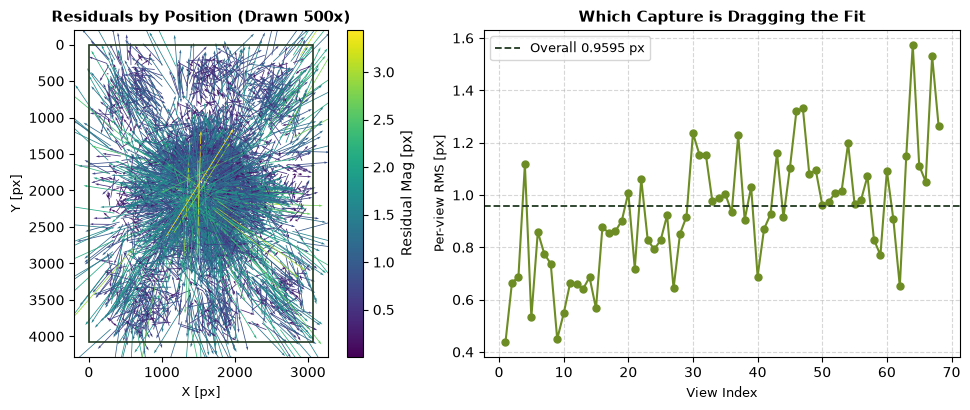

[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\outputs\figures\radial_distortion_curve.png


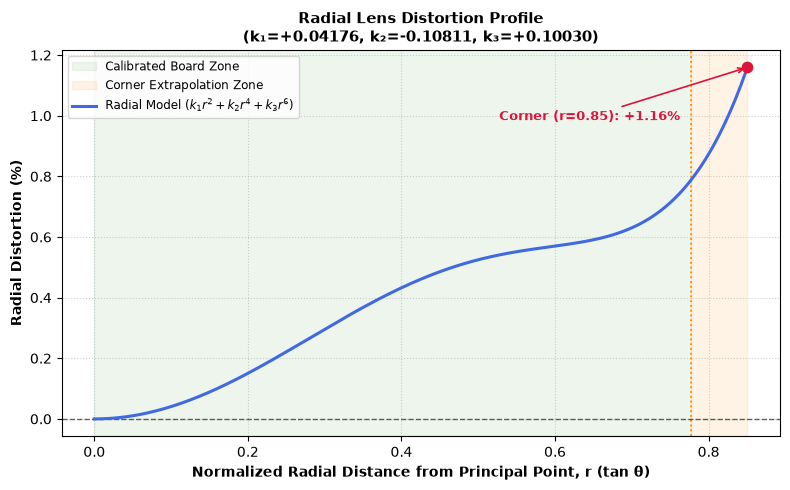

'c:\\Users\\nmmon\\Desktop\\EE513\\Project1\\camera_characterization\\outputs\\figures\\radial_distortion_curve.png'

In [42]:
# ---------------------------------------------------------
# 6. Reprojection Residuals & Radial Distortion Plot
# ---------------------------------------------------------
importlib.reload(plots)
# 2-panel reprojection error diagnostics
plots.plot_calibration_residuals_2panel(
    all_obj_real, all_img_real, calib_payload["rvecs"], calib_payload["tvecs"],
    K_mat, dist_vec, img_shape_real, calib_payload["per_view_rms_errors"], rms,output_dir=output_dir
)


# Radial Distortion Plot

all_pts = np.vstack([c.reshape(-1, 2) for c in all_img_real])
max_cal_r = float(np.max(np.hypot((all_pts[:, 0] - cx) / fx, (all_pts[:, 1] - cy) / fy)))

plots.plot_radial_distortion_curve(
    k1=k1,
    k2=k2,
    k3=k3,
    fx=fx,
    fy=fy,
    cx=cx,
    cy=cy,
    img_width=img_shape_real[0],
    img_height=img_shape_real[1],
    max_calibrated_r=max_cal_r,
    output_dir=output_dir,
)


[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\images\outputs\figures\calibration_summary_table.png


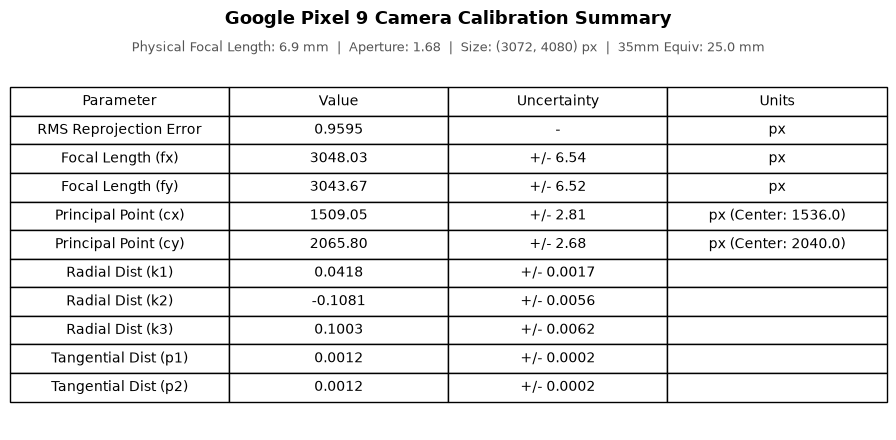

'c:\\Users\\nmmon\\Desktop\\EE513\\Project1\\camera_characterization\\images\\outputs\\figures\\calibration_summary_table.png'

In [13]:
# Summary Table
plots.plot_calibration_summary_table(
    rms, fx, sfx, fy, sfy, cx, scx, cy, scy, k1, sk1, k2, sk2, p1, sp1, p2, sp2, k3, sk3,
    focal_length_mm, f_stop, focal_35mm, img_shape_real
)

### Section 5: Spatial Resolution and Slanted-edge MTF
#### 5.1 Synthetic Simulation Benchmarking

SPATIAL RESOLUTION - SYNTHETIC SIMULATION BENCHMARK
[Sim Edge] NO CLIPPING
  Range: [0.01, 0.53] DN (100x100 px) | Black: 0.00 DN | White: 1.0 DN
[Sim Edge] MARGIN OK
  Edge X Range: [45.6, 54.4] px (100x100 px) | Margins (L/R): 45.6 / 44.6 px
[Sim Edge] Slanted Edge Angle: +5.02° from vertical (84.98° from horizontal) | dx/dy = +0.0878 | R² = 0.9993
Sim QC -> Clip: True | Edge: True | Measured Angle: +5.02 deg
Synthetic Analytic MTF50: 0.1874 c/px
Synthetic Measured MTF50: 0.1843 c/px (Error: 1.66%)
[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\images\outputs\figures\slanted_edge_esf_lsf_mtf.png


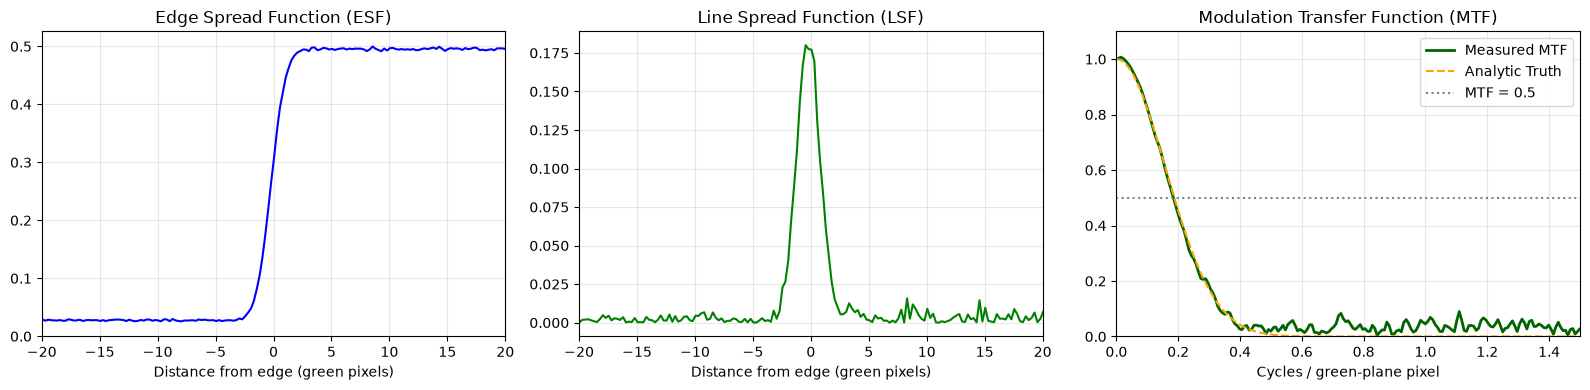

'c:\\Users\\nmmon\\Desktop\\EE513\\Project1\\camera_characterization\\images\\outputs\\figures\\slanted_edge_esf_lsf_mtf.png'

In [14]:
print("=========================================================")
print("SPATIAL RESOLUTION - SYNTHETIC SIMULATION BENCHMARK")
print("=========================================================")

SIGMA = 1.0
edge_sim = simulator.capture_edge(sigma=SIGMA, angle_deg=5.0, h=100, w=100, seed=42)

# Optional: run your QC checks on the synthetic edge (adjust black/white if edge_sim is already [0, 1])
sim_min, sim_max = float(np.min(edge_sim)), float(np.max(edge_sim))
clip_ok = resolution.check_green_roi_clipping(
    edge_sim,
    black_level=0.0,
    white_level=max(1.0, sim_max),
    sat_margin=0.01,
    label="Sim Edge",
)["is_clean"]
edge_ok = resolution.check_green_roi_edge_margins(
    edge_sim, min_margin_px=20.0, label="Sim Edge", show_plot=False
)["edge_ok"]
angle_info = resolution.measure_slant_edge_angle(edge_sim, label="Sim Edge")


print(
    f"Sim QC -> Clip: {clip_ok} | Edge: {edge_ok} | "
    f"Measured Angle: {angle_info.get('angle_from_vertical_deg', np.nan):+.2f} deg"
)

# Normalize if needed (if edge_sim is already normalized [0, 1], black=0.0, white=1.0 is a no-op)
edge_norm = resolution.normalize_view(
    edge_sim, black_level=0.0, white_level=max(1.0, sim_max), clip=False
)

freq_sim, mtf_sim, esf_x_sim, esf_sim = resolution.slanted_edge_mtf(edge_norm)
mtf50_sim_meas = resolution.compute_mtf50(freq_sim, mtf_sim)
mtf50_sim_truth = resolution.analytic_mtf50(SIGMA)

rel_err_pct = abs(mtf50_sim_meas - mtf50_sim_truth) / mtf50_sim_truth * 100.0
print(f"Synthetic Analytic MTF50: {mtf50_sim_truth:.4f} c/px")
print(f"Synthetic Measured MTF50: {mtf50_sim_meas:.4f} c/px (Error: {rel_err_pct:.2f}%)")

lsf_sim = np.abs(np.gradient(esf_sim, esf_x_sim)) if len(esf_x_sim) > 1 else np.zeros_like(esf_sim)
plots.plot_slanted_edge_results(esf_x_sim, esf_sim, lsf_sim, freq_sim, mtf_sim, sigma=SIGMA)

#### 5.2 Real Measurements Slanted-Edge MTF Analysis

In [15]:
print("=========================================================")
print("SPATIAL RESOLUTION - REAL MEASUREMENTS ")
print("=========================================================")

# ---------------------------------------------------------
# 1. Quality Control of Slanted Edge Images
# ---------------------------------------------------------
res_cfg = config.get("resolution", {})
base_dir = Path(res_cfg.get("input_dir", "./images/slanted_edge"))
regions = res_cfg.get("regions", [])
rois_cfg = res_cfg.get("rois", {})

qc_by_region = {}

for idx, region in enumerate(regions):
    if idx > 0:
        print("\n" + "+" * 60 + "\n")

    region_dir = base_dir / region
    if not region_dir.exists():
        print(f"Region: {region} — skipped (directory not found at {region_dir})")
        continue

    dng_paths = utils.get_dng_files(str(region_dir))
    if not dng_paths:
        print(f"Region: {region} — skipped (no DNG files found)")
        continue

    region_roi = rois_cfg.get(region, {}).get("center")
    if not region_roi:
        print(f"Region: {region} — skipped (missing ROI coordinates in config)")
        continue

    print(f"Region: {region} ({len(dng_paths)} files)")
    qc_by_region[region] = resolution.run_qc_audit(
        dng_paths=dng_paths,
        roi_coords=region_roi,
        black_level=black_level,
        white_level=white_level,
        show_edge_plots=False,
    )

SPATIAL RESOLUTION - REAL MEASUREMENTS 
Region: center (5 files)

IMG_20261119_020450.dng
  Angle     : PASS (+5.79°, R²=0.9998)
  Clip Info : PASS | Range: [87.0, 442.0] DN | H:0, L:0
  Edge Info : PASS | L/R Margins: 41.7 / 47.4 px (min 20.0 px)

IMG_20261119_020450~2.dng
  Angle     : PASS (+5.58°, R²=0.9998)
  Clip Info : PASS | Range: [86.0, 440.0] DN | H:0, L:0
  Edge Info : PASS | L/R Margins: 47.5 / 41.8 px (min 20.0 px)

IMG_20261119_020451.dng
  Angle     : PASS (+5.68°, R²=0.9998)
  Clip Info : PASS | Range: [88.0, 439.0] DN | H:0, L:0
  Edge Info : PASS | L/R Margins: 46.5 / 42.6 px (min 20.0 px)

IMG_20261119_020452.dng
  Angle     : PASS (+5.59°, R²=0.9999)
  Clip Info : PASS | Range: [87.0, 439.0] DN | H:0, L:0
  Edge Info : PASS | L/R Margins: 43.5 / 46.1 px (min 20.0 px)

IMG_20261119_020452~2.dng
  Angle     : PASS (+5.73°, R²=0.9998)
  Clip Info : PASS | Range: [86.0, 441.0] DN | H:0, L:0
  Edge Info : PASS | L/R Margins: 46.5 / 42.5 px (min 20.0 px)

Passed quality 

Saved contact sheet to: outputs\figures\slanted_edge_contact_sheet.png


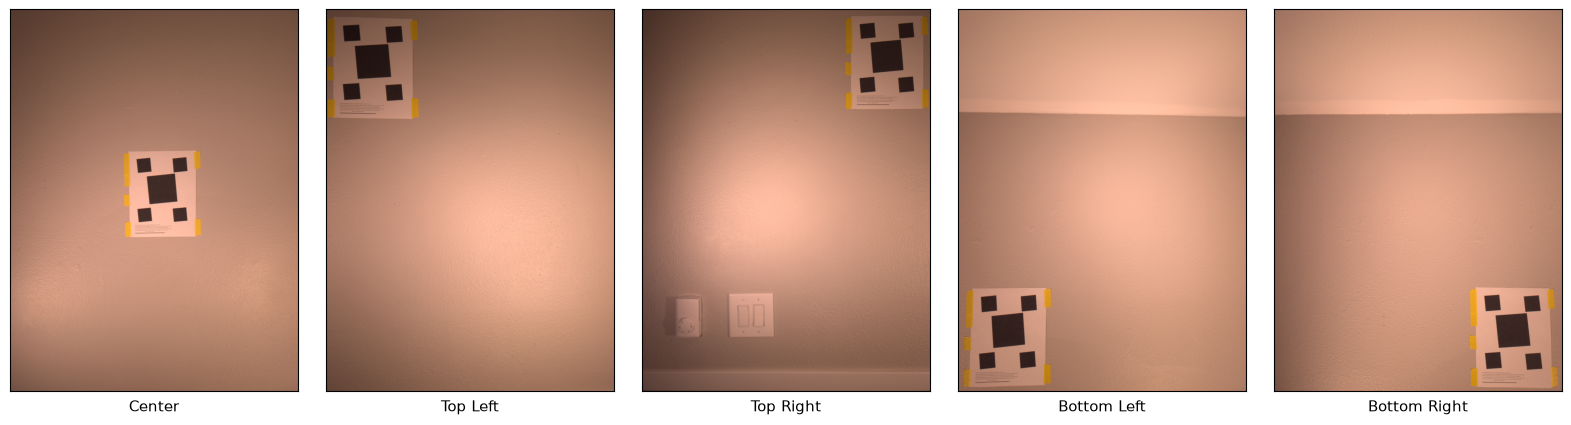

In [16]:
# Collect the first DNG image from each region in order
sample_items = []
for region in regions:
    region_dir = base_dir / region
    if region_dir.exists():
        dng_paths = utils.get_dng_files(str(region_dir))
        if dng_paths:
            sample_items.append((region, dng_paths[0]))

if sample_items:
    fig, axes = plt.subplots(
        1,
        len(sample_items),
        figsize=(3.2 * len(sample_items), 4.2),
        gridspec_kw={"wspace": 0.04, "hspace": 0.0},
    )
    if len(sample_items) == 1:
        axes = [axes]

    for ax, (region, img_path) in zip(axes, sample_items):
        with rawpy.imread(str(img_path)) as raw:
            rgb = raw.postprocess(
                use_camera_wb=True,
                half_size=True,
                no_auto_bright=False,
                output_bps=8,
            )

        ax.imshow(rgb)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel(region.replace("_", " ").title(), fontsize=11, labelpad=6)

    plt.subplots_adjust(left=0.01, right=0.99, top=0.99, bottom=0.08, wspace=0.04)

    figures_dir = Path(output_dir) / "figures"
    figures_dir.mkdir(parents=True, exist_ok=True)
    contact_sheet_path = figures_dir / "slanted_edge_contact_sheet.png"

    plt.savefig(contact_sheet_path, dpi=300, bbox_inches="tight", pad_inches=0.04)
    print(f"Saved contact sheet to: {contact_sheet_path}")
    plt.show()

In [17]:
# ---------------------------------------------------------
# 2. Run MTF50 pipeline for all images that pass QC
# ---------------------------------------------------------

mtf_results_by_region = {}

for idx, (region, qc_data) in enumerate(qc_by_region.items()):
    if idx > 0:
        print("\n" + "+" * 60 + "\n")

    passed_paths = qc_data.get("passed_paths", [])
    region_roi = rois_cfg.get(region, {}).get("center")

    print(f"MTF50 Region: {region} ({len(passed_paths)} passing files)")
    if not passed_paths:
        print("  No images passed all QC checks; skipping MTF50.")
        mtf_results_by_region[region] = None
        continue

    mtf_results_by_region[region] = resolution.process_dng_list_mtf50(
        dng_paths=passed_paths,
        roi_coords=region_roi,
        pixel_pitch_um=p_um,
        black_level=black_level,
        white_level=white_level,
        preview_scale=2.0,
        rotate_k=-1,
    )

MTF50 Region: center (5 passing files)
=== Processing 5 DNG images ===
[IMG_20261119_020450.dng] MTF50: 0.2132 cy/green-px (0.0471 cy/µm | 47.1 cy/mm)
[IMG_20261119_020450~2.dng] MTF50: 0.3519 cy/green-px (0.0777 cy/µm | 77.7 cy/mm)
[IMG_20261119_020451.dng] MTF50: 0.3488 cy/green-px (0.0770 cy/µm | 77.0 cy/mm)
[IMG_20261119_020452.dng] MTF50: 0.3350 cy/green-px (0.0739 cy/µm | 73.9 cy/mm)
[IMG_20261119_020452~2.dng] MTF50: 0.3706 cy/green-px (0.0818 cy/µm | 81.8 cy/mm)
-----------------------------------------------------------------
List Mean MTF50: 0.3239 ± 0.0631 cy/green-px (0.0715 ± 0.0139 cy/µm)
-----------------------------------------------------------------

++++++++++++++++++++++++++++++++++++++++++++++++++++++++++++

MTF50 Region: top_left (5 passing files)
=== Processing 5 DNG images ===
[IMG_20261119_020619.dng] MTF50: 0.1920 cy/green-px (0.0424 cy/µm | 42.4 cy/mm)
[IMG_20261119_020619~2.dng] MTF50: 0.2005 cy/green-px (0.0443 cy/µm | 44.3 cy/mm)
[IMG_20261119_020620.dng] 

In [18]:
# ---------------------------------------------------------
# 3. Summarize center and corner MTF50 results
# ---------------------------------------------------------
importlib.reload(resolution)
center_res = mtf_results_by_region.get("center")
c_mean_px = center_res["mean_px"] if center_res else np.nan
c_std_px = center_res["std_px"] if center_res else np.nan

corner_summary_px = resolution.summarize_corner_mtf50(
    mtf_results_by_region=mtf_results_by_region,
    metric_key="mtf50_px",
) #summarize_corner_mtf50(..., metric_key="mtf50_cy_per_um")

res_payload = {
    "mtf50_center": [float(c_mean_px), float(c_std_px)],
    "mtf50_corner_mean": [
        corner_summary_px["corner_mean"],
        corner_summary_px["total_pooled_std"],  
    ],
    "mtf50_corner_worst": [
        corner_summary_px["corner_worst_mean"],
        corner_summary_px["corner_worst_std"],
    ],
    "mtf50_corner_stds": {
        "uniformity": corner_summary_px["uniformity_std"], # corner-to-corner uniformity std
        "repeatability": corner_summary_px["repeatability_std"],
        "total_pooled": corner_summary_px["total_pooled_std"],
    },
    "corner_details_px": corner_summary_px,
}

print("\n:--- Resolution Payload ---:")
print(f"MTF50 Center:       {res_payload['mtf50_center'][0]:.4f} ± {res_payload['mtf50_center'][1]:.4f} cy/px")
print(f"MTF50 Corner Mean:  {res_payload['mtf50_corner_mean'][0]:.4f} ± {res_payload['mtf50_corner_mean'][1]:.4f} cy/px")
print(f"MTF50 Corner Worst: {res_payload['mtf50_corner_worst'][0]:.4f} ± {res_payload['mtf50_corner_worst'][1]:.4f} cy/px")

stds = res_payload["mtf50_corner_stds"]
print("\nCorner Standard Deviations:")
print(f"  • Uniformity:     {stds['uniformity']:.4f} cy/px")
print(f"  • Repeatability:  {stds['repeatability']:.4f} cy/px")
print(f"  • Total Pooled:   {stds['total_pooled']:.4f} cy/px")

print("\nCorner Details:")
for k, v in res_payload["corner_details_px"].items():
    val_str = f"{v:.4f}" if isinstance(v, (int, float)) else str(v)
    print(f"  • {k}: {val_str}")


:--- Resolution Payload ---:
MTF50 Center:       0.3239 ± 0.0631 cy/px
MTF50 Corner Mean:  0.2381 ± 0.0761 cy/px
MTF50 Corner Worst: 0.1804 ± 0.0301 cy/px

Corner Standard Deviations:
  • Uniformity:     0.0703 cy/px
  • Repeatability:  0.0474 cy/px
  • Total Pooled:   0.0761 cy/px

Corner Details:
  • corner_mean: 0.2381
  • corner_worst_mean: 0.1804
  • corner_worst_std: 0.0301
  • corner_worst_region: top_left
  • uniformity_std: 0.0703
  • repeatability_std: 0.0474
  • total_pooled_std: 0.0761
  • corner_means: [0.18038076303517978, 0.33871846782618675, 0.20202619340662223, 0.2310770056261723]
  • corner_stds: [0.030112070251762654, 0.07800317357751384, 0.021710224748804446, 0.039284811839408344]
  • corner_counts: [5, 5, 5, 5]
  • n_corners: 4.0000
  • n_total_frames: 20.0000


[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\outputs\figures\regional_mtf50_comparison.png


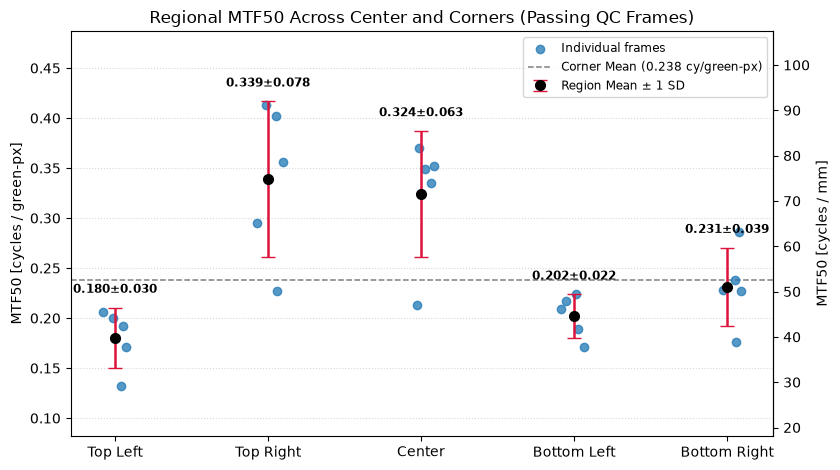

'c:\\Users\\nmmon\\Desktop\\EE513\\Project1\\camera_characterization\\outputs\\figures\\regional_mtf50_comparison.png'

In [19]:
# ---------------------------------------------------------
# 4. Bar plot of MTF50 results by region
# ---------------------------------------------------------
plots.plot_regional_mtf50(
    mtf_results_by_region=mtf_results_by_region,
    res_payload=res_payload,
    pixel_pitch_um=p_um,
    output_dir=output_dir,
)


1. Diffraction Cutoff (v_c):                1.0823 cy/um (1082.25 cy/mm | 4.9034 cy/green-px)
2. Green-Plane Nyquist Frequency:           0.1104 cy/um (110.36 cy/mm | 0.50 cy/green-px)
3. Ratio (v_c / v_Nyquist):                 9.8068
4. Crossover F-number:                      f/8.24
5. Predicted MTF50 (Diff + Green Aper.):    0.5423 cy/green-px (119.7 cy/mm)
6. Predicted Modulation at Nyquist (0.5):   0.5541
[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\images\outputs\figures\predicted_system_mtf.png


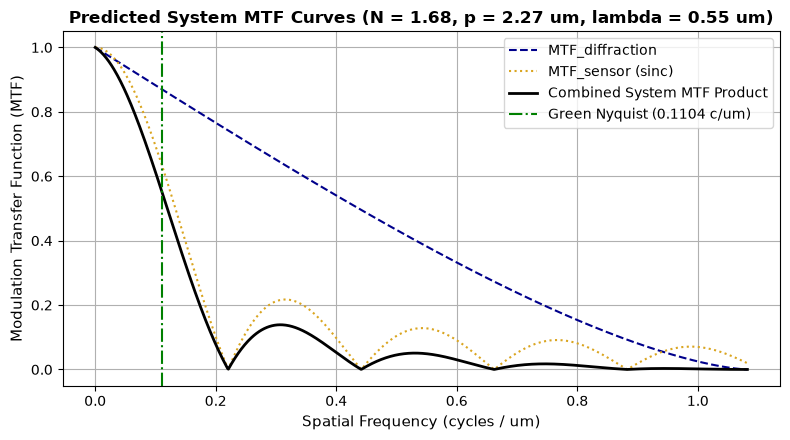

'c:\\Users\\nmmon\\Desktop\\EE513\\Project1\\camera_characterization\\images\\outputs\\figures\\predicted_system_mtf.png'

In [20]:
# ---------------------------------------------------------
# 5. Optical Limits
# ---------------------------------------------------------

NYQUIST_GREEN_PX = 0.5
green_pitch_um = 2.0 * p_um

diffraction_payload = resolution.calculate_diffraction_limits(
    pixel_pitch_um=p_um,
    f_number=f_stop,
    nyquist_green_px=NYQUIST_GREEN_PX,
)
v_c_um = diffraction_payload["v_c_um"]
v_nyquist_um = diffraction_payload["v_nyquist_um"]

pred_mtf50_green_px = diffraction_payload["predicted_mtf50_green_px"]
pred_mtf50_cy_mm = (pred_mtf50_green_px / green_pitch_um) * 1000.0

print(f"1. Diffraction Cutoff (v_c):                {v_c_um:.4f} cy/um ({v_c_um * 1000:.2f} cy/mm | {diffraction_payload['v_c_green_px']:.4f} cy/green-px)")
print(f"2. Green-Plane Nyquist Frequency:           {v_nyquist_um:.4f} cy/um ({v_nyquist_um * 1000:.2f} cy/mm | {NYQUIST_GREEN_PX:.2f} cy/green-px)")
print(f"3. Ratio (v_c / v_Nyquist):                 {v_c_um / v_nyquist_um:.4f}")
print(f"4. Crossover F-number:                      f/{diffraction_payload['crossover_f_number']:.2f}")
print(f"5. Predicted MTF50 (Diff + Green Aper.):    {pred_mtf50_green_px:.4f} cy/green-px ({pred_mtf50_cy_mm:.1f} cy/mm)")
print(f"6. Predicted Modulation at Nyquist (0.5):   {diffraction_payload['modulation_at_nyquist']:.4f}")

plots.plot_predicted_system_mtf(
    diffraction_payload["frequency_axis"],
    diffraction_payload["mtf_diffraction"],
    diffraction_payload["mtf_sensor"],
    diffraction_payload["mtf_total"],
    v_nyquist_um,
    p_um,
    f_stop,
)

In [21]:
# ---------------------------------------------------------
# 6. Measured Modulation at Nyquist for Center Region
# ---------------------------------------------------------
center_dir = base_dir / "center"
center_paths = utils.get_dng_files(str(center_dir)) if center_dir.exists() else []

center_rois_cfg = rois_cfg.get("center", {})
center_roi = center_rois_cfg.get("center", center_rois_cfg) if isinstance(center_rois_cfg, dict) else None

if center_paths and center_roi:
    mod_nyq_center = resolution.measure_modulation_at_nyquist(
        dng_paths=center_paths,
        roi_coords_spec=center_roi,
        nyquist_px=0.5,
        black_level=black_level,
        white_level=white_level,
        pixel_pitch_um=p_um,
    )
    print(f"Center Modulation @ Nyquist (0.5 cy/green-px): {mod_nyq_center:.4f}")

Center Modulation @ Nyquist (0.5 cy/green-px): 0.2526


Plotting IMG_20261119_020450~2.dng | MTF50: 0.3519 cy/green-px
[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\images\outputs\figures\slanted_edge_esf_lsf_mtf.png


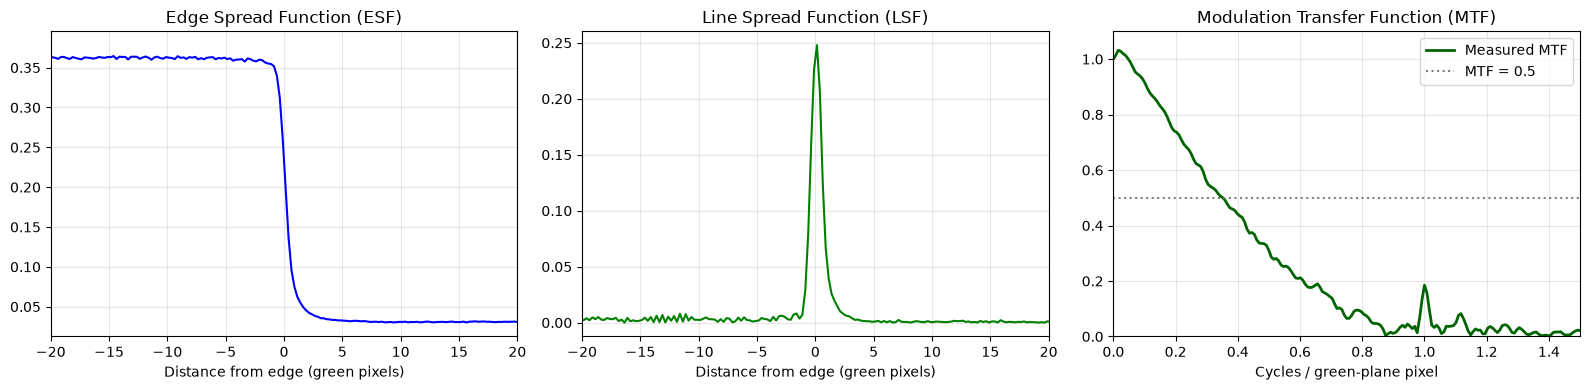

'c:\\Users\\nmmon\\Desktop\\EE513\\Project1\\camera_characterization\\images\\outputs\\figures\\slanted_edge_esf_lsf_mtf.png'

In [22]:
# ---------------------------------------------------------
# 7. Example ESF, LSF, and MTF for a single center frame
# ---------------------------------------------------------

# Pick a region and frame index (e.g., first passing frame in "center")
frame = mtf_results_by_region["center"]["frames"][1]
roi_sub = frame["roi_sub"]

freq, mtf, esf_x, esf = resolution.slanted_edge_mtf(roi_sub)
lsf = np.abs(np.gradient(esf, esf_x)) if len(esf_x) > 1 else np.zeros_like(esf)

print(f"Plotting {frame['filename']} | MTF50: {frame['mtf50_px']:.4f} cy/green-px")
plots.plot_slanted_edge_results(
    esf_x=esf_x,
    esf=esf,
    lsf=lsf,
    freq=freq,
    mtf=mtf,
    sigma=None,  # No synthetic Gaussian sigma for real captures
)

### Section 6: Sensor Noise Model and Photon Transfer Curve
#### 6.1 Synthetic Simulation Benchmarking

In [23]:
print("=========================================================")
print("SENSOR NOISE & PHOTON TRANSFER - Synthetic")
print("=========================================================")

TRUE_K = 0.0213
TRUE_READ = 2.50
SYN_BLACK_LVL = 64.0
SYN_WHITE_LVL = 1023.0

flat_pairs = simulator.generate_flat_field_dataset(true_gain=TRUE_K, true_read_noise=TRUE_READ, black_level=SYN_BLACK_LVL)
dark_series = simulator.generate_synthetic_dark_series(dark_current_e_per_sec=0.45, gain=TRUE_K, read_noise_e=TRUE_READ, black_level=SYN_BLACK_LVL)
cfa_pat = meta.get("cfa_pattern") if "meta" in locals() and isinstance(meta, dict) else None
green_idx = 0

means_above_black, vars_dn2 = [], []
for (f_a, f_b) in flat_pairs:
    mean_sig, var_sig, _ = noise.compute_pair_variance_and_mean(f_a, f_b, black_level=SYN_BLACK_LVL,cfa_pattern=cfa_pat, green_index=green_idx,)
    means_above_black.append(mean_sig)
    vars_dn2.append(var_sig)

gain_K, intercept_c, std_K, valid_mask = noise.fit_photon_transfer_curve(means_above_black, vars_dn2, saturation_fraction=0.70, white_level=SYN_WHITE_LVL, black_level=SYN_BLACK_LVL)
read_noise_e, std_read_noise_e = noise.measure_read_noise_from_dark_frames(dark_series, gain_K, black_level=SYN_BLACK_LVL)

err_K = ((gain_K - TRUE_K) / TRUE_K) * 100.0
err_read = ((read_noise_e - TRUE_READ) / TRUE_READ) * 100.0

print("\n--- SIMULATION RECOVERY BENCHMARK RESULTS ---")
print(f"Recovered Conversion Gain K: {gain_K:.4f} DN/e- (True: {TRUE_K:.4f}) | Error: {err_K:+.2f}%")
print(f"Recovered Read Noise:        {read_noise_e:.2f} e-      (True: {TRUE_READ:.2f}) | Error: {err_read:+.2f}%")
if abs(err_K) < 5.0 and abs(err_read) < 5.0:
    print("PTC and read noise recovery verified within 5%")

SENSOR NOISE & PHOTON TRANSFER - Synthetic

--- SIMULATION RECOVERY BENCHMARK RESULTS ---
Recovered Conversion Gain K: 0.0215 DN/e- (True: 0.0213) | Error: +0.97%
Recovered Read Noise:        2.47 e-      (True: 2.50) | Error: -1.16%
PTC and read noise recovery verified within 5%


#### 6.2 Real Measurements Sensor Noise & PTC Analysis

In [24]:
print("=========================================================")
print("SENSOR NOISE & PHOTON TRANSFER - Real Measurements")
print("=========================================================")
# ---------------------------------------------------------
# 1. Load Flat/Dark DNG Files
# ---------------------------------------------------------
# Read flat-field and dark-frame directory paths from config.yaml
noise_cfg = config.get("noise", {})
flat_dir = noise_cfg.get("flat_dir", "./images/flat_fields")
dark_dir = noise_cfg.get("dark_dir", "./images/dark_frames")

# Scan directories for raw Bayer .dng captures
flat_paths = utils.get_dng_files(flat_dir)
dark_paths = utils.get_dng_files(dark_dir)

print(f"Scanning flat-field folder: '{flat_dir}' (Found {len(flat_paths)} DNG files)")
print(f"Scanning dark-frame folder: '{dark_dir}' (Found {len(dark_paths)} DNG files)")

# Print ISO level for both noise directories. Assert 1 ISO and matching values.
flat_field_isos = exposure_summary["Noise: Flat Fields"]["isos"]
dark_isos = exposure_summary["Noise: Dark Frames"]["isos"]

assert len(flat_field_isos) == 1 and len(dark_isos) == 1, (
    f"Expected a single ISO per noise directory, got flat={flat_field_isos}, dark={dark_isos}"
)
assert flat_field_isos[0] == dark_isos[0], (
    f"ISO mismatch between Flat Fields ({flat_field_isos[0]}) and Dark Frames ({dark_isos[0]})"
)

flat_field_level_iso = flat_field_isos[0]
dark_level_iso = dark_isos[0]

print(f"Verified Noise ISO — Flat Fields: {flat_field_level_iso}, Dark Frames: {dark_level_iso}")

SENSOR NOISE & PHOTON TRANSFER - Real Measurements
Scanning flat-field folder: './images/flat_fields' (Found 24 DNG files)
Scanning dark-frame folder: './images/dark_frames' (Found 30 DNG files)
Verified Noise ISO — Flat Fields: 22, Dark Frames: 22


In [25]:
# -------------------------------------------------------------------
# 2. Pair Flat-Field Frames by Exposure & Cancel Fixed-Pattern Noise
# -------------------------------------------------------------------

# Initialize signal/variance lists and extract global black/white/CFA settings
means_above_black, vars_dn2 = [], []
black_lvl = float(black_level)
white_lvl = float(white_level)
cfa_pat = meta.get("cfa_pattern") if "meta" in locals() and isinstance(meta, dict) else None
green_idx = 0

#Prints exposure matches
if len(flat_paths) >= 2:
     # Group flat-field captures by identical shutter speed so each pair shares the same illumination
    exposure_groups, raw_exposure_map = utils.group_files_by_exposure(flat_paths)
    print("\n:--- Exposure Pairing & Calculated Metrics Table ---:\n")
    print("| Shutter Speed |         File A          |           File B          | Mean Signal Above Black (DN) |  Pair Variance (DN^2)  |         Status       |")
    print("| :-------------| :---------------------- | :------------------------ | :--------------------------- | :----------------------|  :------------------ |")

     # Define 70% saturation cutoff to exclude non-linear full-well clipping near 1023 DN
    sat_threshold_dn = 0.70 * (white_lvl - black_lvl)

    for exp_key in sorted(exposure_groups.keys()):
        paths = exposure_groups[exp_key]
        if len(paths) >= 2:
            path_a, path_b = paths[0], paths[1]
            if path_a == path_b:
                continue

            # Subtract frame A - frame B on the center 256x256 green plane to cancel FPN/PRNU
            # and return (mean_above_black, 0.5 * Var[A - B], mean_black)
            mean_sig, var_sig, _ = noise.compute_pair_variance_and_mean(
                path_a,
                path_b,
                black_level=black_lvl,
                cfa_pattern=cfa_pat,
                green_index=green_idx,
            )
            if var_sig > 0:
                means_above_black.append(mean_sig)
                vars_dn2.append(var_sig)
                shutter_label = utils.format_shutter_speed(raw_exposure_map[exp_key])
                file_a_name = Path(path_a).name
                file_b_name = Path(path_b).name
                status = "Included" if mean_sig <= sat_threshold_dn else "Excluded (>70% Sat)"
                print(
                    f"| {shutter_label:<13} | {file_a_name:<20} | {file_b_name:<20} | "
                    f"{mean_sig:28.2f} | {var_sig:22.2f} | {status:<18} |"
                )
else:
    # Fallback synthetic Poisson-Gaussian benchmark if real flat-field DNGs are missing
    print("Real flat-field captures not found. Running benchmark simulation...")
    true_K, true_read_e, black_lvl, white_lvl = 0.0213, 2.5, 64.0, 1023.0
    flat_pairs = simulator.generate_flat_field_dataset(
        true_gain=true_K, true_read_noise=true_read_e, black_level=black_lvl
    )
    for f_a, f_b in flat_pairs:
        mean_sig, var_sig, _ = noise.compute_pair_variance_and_mean(
            f_a, f_b, black_level=black_lvl
        )
        means_above_black.append(mean_sig)
        vars_dn2.append(var_sig)

# ---------------------------------------------------------
# 3. Fit Linear Photon Transfer Curve (Conversion Gain K)
# ---------------------------------------------------------
# Fit Var[D] = K * (Mean[D] - B) + c on unsaturated points (<70% saturation) to recover K and std_K
gain_K, intercept_c, std_K, valid_mask = noise.fit_photon_transfer_curve(
    means_above_black,
    vars_dn2,
    saturation_fraction=0.70,
    white_level=white_lvl,
    black_level=black_lvl,
)
print(f"{len(valid_mask)} pairs: {valid_mask}")
print(f"Conversion Gain K:   {gain_K:.4f} +/- {std_K:.2e} DN/e-")
print(f"Intercept C:   {intercept_c:.4f} DN^2")




:--- Exposure Pairing & Calculated Metrics Table ---:

| Shutter Speed |         File A          |           File B          | Mean Signal Above Black (DN) |  Pair Variance (DN^2)  |         Status       |
| :-------------| :---------------------- | :------------------------ | :--------------------------- | :----------------------|  :------------------ |
| 1/45s         | IMG_20261108_095043.dng | IMG_20261108_095043~2.dng |                        14.18 |                   0.93 | Included           |
| 1/40s         | IMG_20261108_095112.dng | IMG_20261108_095112~2.dng |                        15.98 |                   0.95 | Included           |
| 1/35s         | IMG_20261108_095118.dng | IMG_20261108_095118~2.dng |                        18.23 |                   0.97 | Included           |
| 1/30s         | IMG_20261108_095129.dng | IMG_20261108_095129~2.dng |                        21.24 |                   1.03 | Included           |
| 1/25s         | IMG_20261108_095144.dng | IM

In [26]:
# ---------------------------------------------------------------------
# 4. Measure Read Noise & Thermal Dark Current From Capped Dark Frames
# ---------------------------------------------------------------------

has_dark_series = len(dark_paths) >= 2
if has_dark_series:
    # Group capped dark frames by exposure time (from shortest ~1/39695s up to 16.0s)
    dark_exposure_groups, dark_raw_exposure_map = utils.group_files_by_exposure(dark_paths)
    print("\n:--- Dark Frames Per Exposure Time ---:\n")

    for exp_key in sorted(dark_exposure_groups.keys()):
        paths = dark_exposure_groups[exp_key]
        shutter_label = utils.format_shutter_speed(dark_raw_exposure_map[exp_key])
        print(f"Shutter Speed: {shutter_label} ({len(paths)} files)")
        for file_path in paths:
            print(f"   ↳ {Path(file_path).name}")
        print()

    # Measure read noise floor (in e-) from the shortest-exposure dark pair where dark current ≈ 0
    read_noise_e, std_read_noise_e = noise.measure_read_noise_from_dark_frames(
        dark_paths,
        gain_K=gain_K,
        black_level=black_lvl,
        cfa_pattern=cfa_pat,
        green_index=green_idx,
    )

    # Fit linear slope of dark electrons vs. exposure time (in e-/s) across all dark series exposures
    dark_current_val, std_dark_current = noise.fit_dark_current(
        dark_exposure_groups,
        gain_K=gain_K,
        black_level=black_lvl,
        cfa_pattern=cfa_pat,
        green_index=green_idx,
    )
else:
    read_noise_e, std_read_noise_e = float("nan"), float("nan")
    dark_current_val, std_dark_current = float("nan"), float("nan")

print(f"Read Noise:    {read_noise_e:.4f} +/- {std_read_noise_e:.4f} e-")
print(f"Dark Current:  {dark_current_val:.4f} +/- {std_dark_current:.4f} e-")


:--- Dark Frames Per Exposure Time ---:

Shutter Speed: 1/39695s (5 files)
   ↳ IMG_20261108_094513.dng
   ↳ IMG_20261108_094513~2.dng
   ↳ IMG_20261108_094514.dng
   ↳ IMG_20261108_094514~2.dng
   ↳ IMG_20261108_094514~3.dng

Shutter Speed: 1/1005s (5 files)
   ↳ IMG_20261108_094526.dng
   ↳ IMG_20261108_094526~2.dng
   ↳ IMG_20261108_094526~3.dng
   ↳ IMG_20261108_094527.dng
   ↳ IMG_20261108_094527~2.dng

Shutter Speed: 1/501s (5 files)
   ↳ IMG_20261108_094534.dng
   ↳ IMG_20261108_094534~2.dng
   ↳ IMG_20261108_094534~3.dng
   ↳ IMG_20261108_094534~4.dng
   ↳ IMG_20261108_094535.dng

Shutter Speed: 1/10s (5 files)
   ↳ IMG_20261108_094546.dng
   ↳ IMG_20261108_094547.dng
   ↳ IMG_20261108_094547~2.dng
   ↳ IMG_20261108_094548.dng
   ↳ IMG_20261108_094549.dng

Shutter Speed: 2.0s (5 files)
   ↳ IMG_20261108_094559.dng
   ↳ IMG_20261108_094603.dng
   ↳ IMG_20261108_094606.dng
   ↳ IMG_20261108_094610.dng
   ↳ IMG_20261108_094614.dng

Shutter Speed: 16.0s (5 files)
   ↳ IMG_20261108

In [27]:
# -------------------------------------------------------------------------
# 5. Compute Full-Well Capacity, Dynamic Range & Vendor Metadata Benchmark
# -------------------------------------------------------------------------

# Convert linear digital saturation span (white - black) into photo-electrons
full_well_e = dynamics.compute_full_well_capacity(white_lvl, black_lvl, gain_K)

# Compute engineering Dynamic Range (SNR = 1 criterion) in stops/dB and propagate uncertainties
dr_stops, dr_db, std_dr_stops = dynamics.calculate_dynamic_range(
    full_well_e,
    read_noise_e,
    snr_threshold=1.0,
    std_gain_k=std_K,
    gain_k=gain_K,
    std_read_noise_e=std_read_noise_e,
)

print(f"Dynamic Range: {dr_stops:.2f} +/- {std_dr_stops:.2f} stops\n")
print(f"Dynamic Range: {dr_db:.2f} DB\n")


Dynamic Range: 10.14 +/- 0.07 stops

Dynamic Range: 61.02 DB



In [28]:
# ---------------------------------------------------------
# 7. Manufacturer Noise Profile
# ---------------------------------------------------------

# Extract factory DNG NoiseProfile (Tag 51041) to cross-check empirical gain and read noise

#2. Scales normalized parameters back to physical sensor units using `span = white_level - black_level`:
# Conversion gain: `K_vendor = S * span` (DN/e-)
# Read noise: `rn_dn = sqrt(O) * span` (DN) and `rn_e = sqrt(O) / S` (e-)

profiles = {
    tuple(noise.get_vendor_noise_profile(p, black_level=black_level, white_level=white_level)["raw_pairs_S_O"])
    for p in (flat_paths + dark_paths)
}
print(f"Unique NoiseProfile tags across all {len(flat_paths + dark_paths)} ISO 22 files: {len(profiles)}")


vendor_profile = None
if flat_paths:
    vendor_profile = noise.get_vendor_noise_profile(
        flat_paths[0], black_level=black_level, white_level=white_level
    )


print(":--- Vendor NoiseProfile (Tag 51041) ---:")
print(
    "Raw (S, O) pairs per channel  : "
    f"{[(f'{s:.2e}', f'{o:.2e}') for s, o in vendor_profile['raw_pairs_S_O']]}"
)
print(
    "Vendor Gain (K) per channel   : "
    f"{[round(x, 5) for x in vendor_profile['k_vendor_dn_per_e']]} DN/e- "
    f"({[round(x, 2) for x in vendor_profile['gain_vendor_e_per_dn']]} e-/DN)"
)
print(
    "Vendor Read Noise per channel : "
    f"{[round(x, 2) for x in vendor_profile['read_noise_vendor_e']]} e- "
    f"({[round(x, 2) for x in vendor_profile['read_noise_vendor_dn']]} DN)"
)
print(
    f"Mean Vendor Gain (K)          : {vendor_profile['mean_k_dn_per_e']:.5f} DN/e- "
    f"({vendor_profile['mean_gain_e_per_dn']:.2f} e-/DN)"
)
print(
    f"Mean Vendor Read Noise        : {vendor_profile['mean_read_noise_e']:.2f} e- "
    f"({vendor_profile['mean_read_noise_dn']:.2f} DN)"
)
print(f"Dynamic Span: {vendor_profile["dynamic_span_dn"]:.2f} DN")


Unique NoiseProfile tags across all 54 ISO 22 files: 1
:--- Vendor NoiseProfile (Tag 51041) ---:
Raw (S, O) pairs per channel  : [('2.22e-05', '7.99e-07'), ('2.33e-05', '7.99e-07'), ('2.34e-05', '8.00e-07')]
Vendor Gain (K) per channel   : [0.02125, 0.02239, 0.02245] DN/e- ([47.06, 44.66, 44.54] e-/DN)
Vendor Read Noise per channel : [40.35, 38.29, 38.22] e- ([0.86, 0.86, 0.86] DN)
Mean Vendor Gain (K)          : 0.02203 DN/e- (45.42 e-/DN)
Mean Vendor Read Noise        : 38.95 e- (0.86 DN)
Dynamic Span: 959.02 DN


In [29]:
# Package noise and dynamics metrics for results.json export
noise_payload = {
    "K": [float(gain_K), float(std_K)],
    "read_noise": [float(read_noise_e), float(std_read_noise_e)],
    "dark_current": [float(dark_current_val), float(std_dark_current)],
    "iso": dark_level_iso,
    "black_level": [bl_mean, bl_std],
    "white_level": int(white_level),
    "vendor_noiseprofile_present": vendor_profile is not None,
    "dr_stops": [float(dr_stops), float(std_dr_stops)],
    "dr_criterion": "SNR = 1 at low end",
}

print("\n:--- PTC & Noise Results ---:")
print(f"Conversion Gain K:   {gain_K:.4f} +/- {std_K:2e} DN/e-")
print(f"Read Noise:          {read_noise_e:.2f} +/- {std_read_noise_e:.2f} e-")
print(f"Dark Current:        {dark_current_val:.2f} +/- {std_dark_current:.2f} e-/s")
print(f"Full Well Capacity:  {full_well_e:.1f} e-")
print(f"Dynamic Range:       {dr_stops:.2f} +/- {std_dr_stops:.2f} stops")
print(f"Black Level:         {bl_mean:.4f} ± {bl_std:.4f} DN (N={black_level_samples} frames [dark_frames + flat_fields] at ISO {dark_level_iso})")
print(f"White Level:         {white_level}")


:--- PTC & Noise Results ---:
Conversion Gain K:   0.0148 +/- 3.689942e-05 DN/e-
Read Noise:          57.76 +/- 2.89 e-
Dark Current:        16.46 +/- 0.31 e-/s
Full Well Capacity:  64965.7 e-
Dynamic Range:       10.14 +/- 0.07 stops
Black Level:         63.9841 ± 0.0138 DN (N=54 frames [dark_frames + flat_fields] at ISO 22)
White Level:         1023.0


[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\images\outputs\figures\ptc_curve.png


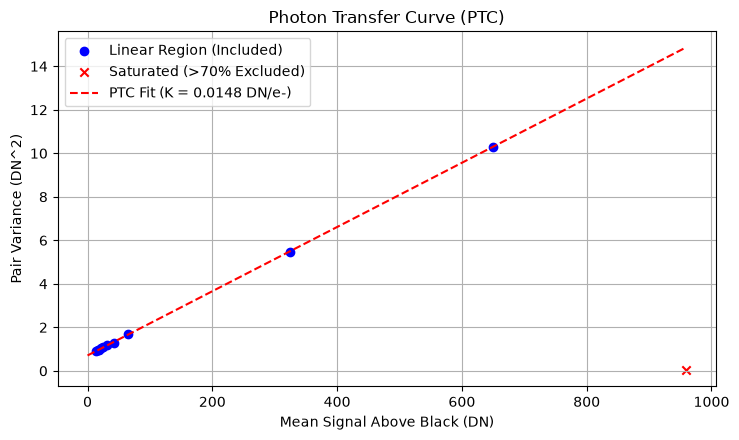

[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\outputs\figures\snr_chart.png


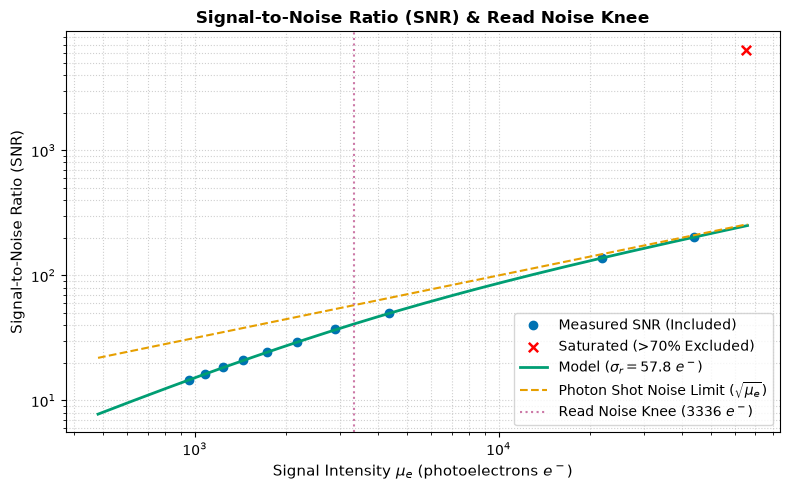

[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\outputs\figures\dark_current_fit.png


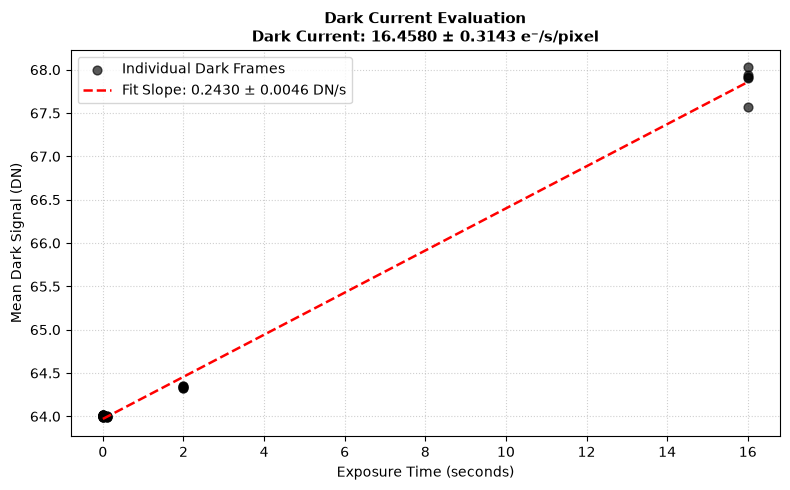

In [30]:
# ---------------------------------------------------------
# 8. Render & Save Diagnostic Plots (PTC, SNR & Dark Current)
# ---------------------------------------------------------
# Plot 1: Photon Transfer Curve (Variance vs. Mean Signal Above Black)
plots.plot_ptc_curve(means_above_black, vars_dn2, valid_mask, gain_K, intercept_c)
importlib.reload(plots)
# Plot 2: Signal-to-Noise Ratio (SNR) vs. Photo-electrons across read-noise and shot-noise regimes
plots.plot_snr_curve(
    means=means_above_black,
    var_pair=vars_dn2,
    K=gain_K,
    read_noise_e=read_noise_e,
    output_dir=output_dir,
    filename="snr_chart.png",
    valid_mask=valid_mask,
)

# Plot 3: Linear Thermal Dark Current Fit across exposure times
if has_dark_series and np.isfinite(dark_current_val):
    plots.plot_dark_current(
        dark_exposure_groups=dark_exposure_groups,
        gain_K=gain_K,
        dark_current_e_sec=dark_current_val,
        dark_current_err=std_dark_current,
        black_level=black_lvl,
        cfa_pattern=cfa_pat,
        green_index=green_idx,
        output_dir=output_dir,
        filename="dark_current_fit.png",
    )

### Section 7: Color Calibration and Color Correction Matrix
#### 7.1 Synthetic & Real Color Science Evaluation

In [ ]:
print("=========================================================")
print("STAGE 4: Color Calibration - Synthetic")
print("=========================================================")

"""
This synthetic color trial tests whether the white-balancing (compute_white_balance_gains),
CCM least-squares solver (fit_color_correction_matrix), and CIEDE2000 evaluator (evaluate_delta_e)
recover the exact ground-truth ColorChecker XYZ values (0.00 ΔE00 error) when given a simulated
camera with known spectral cross-talk and illuminant shifts.
"""
#Ground truth = ColorChecker24 - After November 2014 under Illuminant D50
ref_xyz = color.COLORCHECKER_REF_XYZ

# Simulated R G B sensor channel response to [X, Y, Z]
# Different channel sensitivities (2.85, 1.80, 1.15): Simulates unequal
# R/G/B filter transmission. Off-diagonal cross-talk: Simulates spectral
# overlap between the R, G, and B color filters (whyraw camera RGB does not match sRGB before a CCM).
# 0.00 ΔE00 is achievable here because sim_rgb is generated by a linear 3 × 3
# transformation of ref_xyz (ref_xyz @ sensor_sens.T), it satisfies the Luther–Ives condition
# by construction—so an exact linear inverse CCM exists, proving code is ready if led_xyz_rmse ≈ 1e-15 and ΔE00 = 0.00.
sensor_sens = np.array([
    [2.85, -0.45, 0.10],
    [-0.35,  1.80, -0.20],
    [0.05, -0.30,  1.15],
], dtype=np.float64)

#per-channel [R, G, B] white-balance multipliers
#Synthetic diagonal white-point shifts modeling how different light sources change the relative [R, G, B] energy hitting the sensor 
illuminant_shifts = {
    "LED":          np.array([0.94, 1.03, 1.12], dtype=np.float64), # Slightly blue-weighted LED light
    "Outdoors":     np.array([1.00, 1.00, 1.00], dtype=np.float64), # Neutral D50/daylight baseline
    "Overhead":     np.array([1.08, 1.00, 0.92], dtype=np.float64), # Slightly warm overhead lamp
    "Incandescent": np.array([1.28, 0.96, 0.72], dtype=np.float64), # Warm tungsten (heavy Red, weak Blue)
}

# Maps standard linear sRGB primaries ([R, G, B]) into CIE 1931 XYZ tristimulus coordinates ([X, Y, Z])
srgb_matrix = color.SRGB_TO_XYZ

# Setting noise_std = 0.0 makes the test analytically exact:
# because the synthetic camera (sensor_sens) is a pure linear 3 × 3 transform of ref_xyz,
# a noiseless least-squares fit must recover ref_xyz down to floating-point machine precision
# (~10⁻¹⁵ RMSE, 0.00 ΔE00). Raising it (e.g., 0.002) tests how well least squares resists measurement noise.
noise_std = 0.0  # Set > 0.0 (e.g., 0.002) to test noisy patch recovery
seed = 42

#Takes the 24 true ref_xyz patches, multiplies them by sensor_sens.T
# (simulating a camera with unequal R/G/B sensitivity and channel cross-talk),
# and scales R, G, and B by illuminant_shifts["LED"] to simulate colored lighting.
led_raw, _ = simulator.generate_synthetic_color_patches(
    ref_xyz=ref_xyz,
    sensor_matrix=sensor_sens,
    illuminant_rgb_gains=illuminant_shifts["LED"],
    black_level_norm=0.0,
    white_level_norm=1.0,
    noise_std=noise_std,
    seed=seed,
)

# Uses neutral mid-gray Patch 21 (idx = 20) to compute diagonal gains
# (g_R = G/R, g_G = 1, g_B = G/B) and cancels the LED illuminant tint.
_, led_balanced = color.compute_white_balance_gains(led_raw, neutral_patch_idx=20)
baseline_xyz = led_balanced @ srgb_matrix.T
meas_white_base = baseline_xyz[18]

# Converts the white-balanced camera RGB to XYZ using srgb_matrix.T
# without correcting for sensor_sens cross-talk, then computes CIEDE2000
# (mean_de_before) to establish the uncalibrated baseline error.
mean_de_before, std_de_before, _, de_before_list = color.evaluate_delta_e(
    baseline_xyz, ref_xyz, white_ref_xyz=meas_white_base
)

#Solves led_balanced @ CCM.T ≈ ref_xyz via linear least squares (np.linalg.lstsq)
CCM = color.fit_color_correction_matrix(led_balanced, ref_xyz)


# Maps led_corrected_xyz = led_balanced @ CCM.T and verifies
# led_xyz_rmse ≈ 1e-15 and ΔE00 = 0.00 - proving the matrix transpose
# orientation and white-point scaling are ready for real DNGs
led_corrected_xyz = led_balanced @ CCM.T
# Exact linear XYZ recovery metrics on the calibration ("LED") set
led_xyz_rmse = np.sqrt(np.mean((led_corrected_xyz - ref_xyz) ** 2))
led_xyz_max_err = np.max(np.abs(led_corrected_xyz - ref_xyz))
led_lum_mae = np.mean(np.abs(led_corrected_xyz[:, 1] - ref_xyz[:, 1]))

# Multi-illuminant evaluation pass (repeat steps under three other
# illuminant multipliers, refits white balance per illuminant, and applied
# the fixed LED CCM unchanged, confirming 0.00 ΔE00 recovery when
# illuminant changes are purely diagonal.)
summary_results = {}
per_patch_errors = {}

for idx, (name, shift) in enumerate(illuminant_shifts.items()):
    raw_rgb, _ = simulator.generate_synthetic_color_patches(
        ref_xyz=ref_xyz,
        sensor_matrix=sensor_sens,
        illuminant_rgb_gains=shift,
        black_level_norm=0.0,
        white_level_norm=1.0,
        noise_std=noise_std,
        seed=seed + idx + 1,
    )
    _, bal_means = color.compute_white_balance_gains(raw_rgb, neutral_patch_idx=20)
    corrected_xyz = bal_means @ CCM.T
    # meas_white_xyz = bal_means[18] @ srgb_matrix.T

    m_de, s_de, w_de, de_list = color.evaluate_delta_e(
        corrected_xyz, ref_xyz#, white_ref_xyz=meas_white_xyz
    )
    illum_xyz_rmse = np.sqrt(np.mean((corrected_xyz - ref_xyz) ** 2))

    summary_results[name] = {
        "mean_de": m_de,
        "std_de": s_de,
        "worst_de": w_de,
        "xyz_rmse": illum_xyz_rmse,
    }
    per_patch_errors[name] = de_list

print(f"[SIM] Mean CIEDE2000 ΔE_00 BEFORE CCM : {mean_de_before:.2f} ± {std_de_before:.2f}")
print(f"[SIM] Mean CIEDE2000 ΔE_00 AFTER CCM  : {summary_results['LED']['mean_de']:.2f} ± {summary_results['LED']['std_de']:.2f}")
print(f"[SIM] Worst Patch  ΔE_00 AFTER CCM   : {summary_results['LED']['worst_de']:.2f}\n")

print("--- [SIM] Multi-Illuminant Performance ---")
print(f"{'Illuminant':<15} | {'Mean Delta E00':<15} | {'Worst Delta E00':<15} | {'XYZ RMSE'}")
print("-" * 72)
for name, res in summary_results.items():
    print(
        f"{name:<15} | {res['mean_de']:6.2f} +/- {res['std_de']:4.2f} | "
        f"{res['worst_de']:15.2f} | {res['xyz_rmse']:.6e}"
    )
print("-" * 72)

print("\n[SIM] Fitted 3x3 Color Correction Matrix (CCM):")
print(np.round(CCM, 4))

print(f"\n[SIM] LED XYZ RMSE       : {led_xyz_rmse:.6e}")
print(f"[SIM] LED Max XYZ Error  : {led_xyz_max_err:.6e}")
print(f"[SIM] LED Luminance MAE  : {led_lum_mae:.6e}")

STAGE 4: Color Calibration - Synthetic
[SIM] Mean CIEDE2000 ΔE_00 BEFORE CCM : 12.74 ± 6.60
[SIM] Mean CIEDE2000 ΔE_00 AFTER CCM  : 0.00 ± 0.00
[SIM] Worst Patch  ΔE_00 AFTER CCM   : 0.00

--- [SIM] Multi-Illuminant Performance ---
Illuminant      | Mean Delta E00  | Worst Delta E00 | XYZ RMSE
------------------------------------------------------------------------
LED             |   0.00 +/- 0.00 |            0.00 | 1.255176e-16
Outdoors        |   0.00 +/- 0.00 |            0.00 | 8.999523e-03
Overhead        |   0.00 +/- 0.00 |            0.00 | 8.999523e-03
Incandescent    |   0.00 +/- 0.00 |            0.00 | 2.099889e-02
------------------------------------------------------------------------

[SIM] Fitted 3x3 Color Correction Matrix (CCM):
[[ 0.6391  0.0852 -0.0084]
 [ 0.1248  0.5721  0.0502]
 [ 0.0048  0.1455  0.4668]]

[SIM] LED XYZ RMSE       : 1.255176e-16
[SIM] LED Max XYZ Error  : 3.330669e-16
[SIM] LED Luminance MAE  : 1.552578e-16


In [32]:
print("Check Simulated Incandescent at Patch 19")
print("\nref_xyz[18]      :", ref_xyz[18])
print("corrected_xyz[18]:", corrected_xyz[18])
print("ratio Y (corr/ref):", corrected_xyz[18, 1] / ref_xyz[18, 1])

Check Simulated Incandescent at Patch 19

ref_xyz[18]      : [ 0.84369853  0.88069032  0.69367788]
corrected_xyz[18]: [ 0.78635979  0.82083758  0.64653472]
ratio Y (corr/ref): 0.932038834951


#### 7.2 Real Color Calibration 

STAGE 4: Color Calibration - Real
[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\outputs\figures\color_raw_histograms.png


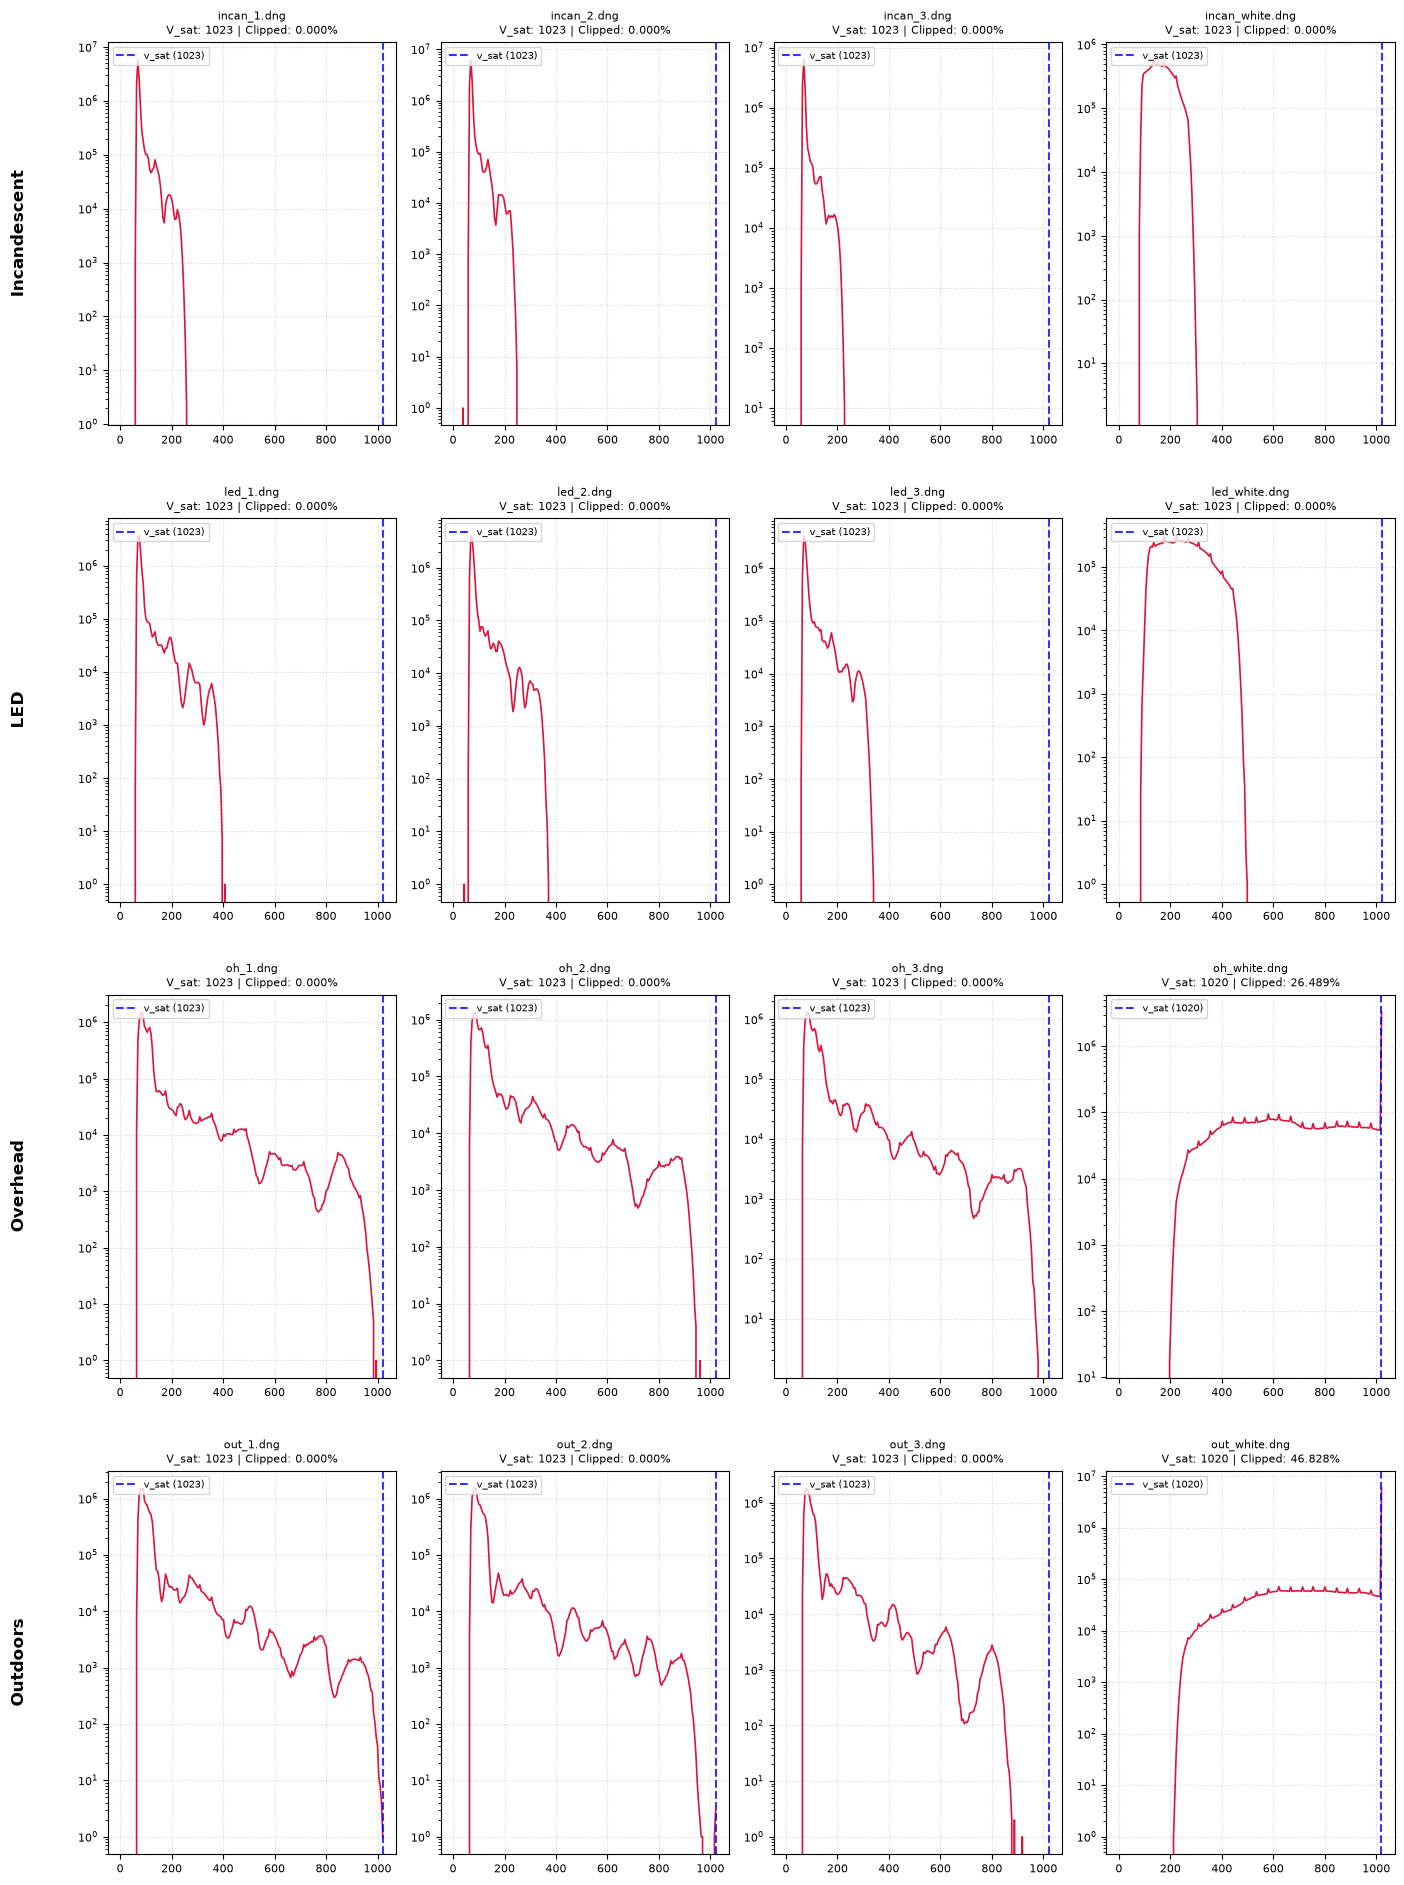

[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\outputs\figures\white_sheet_horizontal_profiles.png


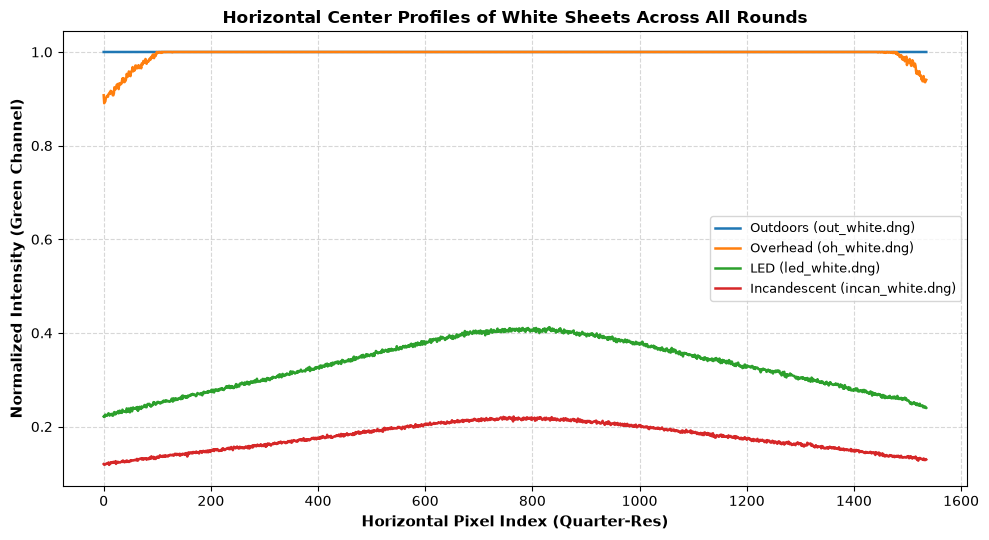


=== Corner-to-Center Ratios Across All White Sheets ===

--- Outdoors White Sheet ---
  Red   Channel -> Before: 0.3647 | After: 1.0000
  Green Channel -> Before: 0.7316 | After: 1.0000
  Blue  Channel -> Before: 0.5496 | After: 1.0000

--- Overhead White Sheet ---
  Red   Channel -> Before: 0.3795 | After: 1.0000
  Green Channel -> Before: 0.5723 | After: 1.0000
  Blue  Channel -> Before: 0.3536 | After: 1.0000

--- LED White Sheet ---
  Red   Channel -> Before: 0.2807 | After: 1.0000
  Green Channel -> Before: 0.2815 | After: 1.0000
  Blue  Channel -> Before: 0.2797 | After: 1.0000

--- Incandescent White Sheet ---
  Red   Channel -> Before: 0.2778 | After: 1.0000
  Green Channel -> Before: 0.2840 | After: 1.0000
  Blue  Channel -> Before: 0.2844 | After: 1.0000


In [33]:
print("=========================================================")
print("STAGE 4: Color Calibration - Real")
print("=========================================================")

# ---------------------------------------------------------
# 1. Check Captures for Clipping
# ---------------------------------------------------------
color_cfg = config.get("color", {})
COLORCHECKER_BBOXES = color_cfg.get("bboxes", color.COLORCHECKER_BBOXES)
real_color_dir = color_cfg.get("input_dir", "./images/color_checker")
if not os.path.exists(real_color_dir) or len(utils.get_dng_files(real_color_dir)) == 0:
    real_color_dir = None

#Histogram check
if real_color_dir:
    all_color_files = sorted(utils.get_dng_files(real_color_dir))
    plots.plot_raw_saturation_histograms(all_color_files, output_dir=output_dir)

#White Field Horizontal Plot Check
white_sheet_paths = {
    "Outdoors":     os.path.join(real_color_dir, "out_white.dng"),
    "Overhead":     os.path.join(real_color_dir, "oh_white.dng"),
    "LED":          os.path.join(real_color_dir, "led_white.dng"),
    "Incandescent": os.path.join(real_color_dir, "incan_white.dng"),
}
ws_ratios = plots.plot_white_sheet_horizontal_profiles(
    white_sheet_paths=white_sheet_paths,
    black_level=black_level,
    output_dir=output_dir,
)

In [34]:
# ---------------------------------------------------------
# 2. Set illuminant configuration
# ---------------------------------------------------------
# Set flat field configuration with LED white sheet that did not clip
illuminant_config = {
    "LED":          {"scene": "led_1.dng",   "white": "led_white.dng",   "bbox": COLORCHECKER_BBOXES.get("led_1.dng", [480, 1500, 400, 1100])},
    "Outdoors":     {"scene": "out_3.dng",   "white": "led_white.dng",   "bbox": COLORCHECKER_BBOXES.get("out_3.dng", [420, 1660, 370, 1190])},
    "Overhead":     {"scene": "oh_1.dng",    "white": "led_white.dng",   "bbox": COLORCHECKER_BBOXES.get("oh_1.dng", [395, 1515, 395, 1120])},
    "Incandescent": {"scene": "incan_1.dng", "white": "led_white.dng",   "bbox": COLORCHECKER_BBOXES.get("incan_1.dng", [500, 1515, 395, 1070])}
}

Processing Real Color Captures from: ./images/color_checker

Fitted 3x3 Color Correction Matrix (CCM):
[[ 1.1323  0.641   0.3815]
 [-0.1091  2.3368  0.0538]
 [-0.0606 -1.9705  3.8475]]
Mean CIEDE2000 ΔE_00 BEFORE CCM : 12.34 ± 4.72
Worst Patch  ΔE_00 BEFORE CCM  : 19.45 (16. Yellow)
Mean CIEDE2000 ΔE_00 AFTER CCM  : 3.49 ± 2.14
Worst Patch  ΔE_00 AFTER CCM   : 11.20 (15. Red)

[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\outputs\figures\color_delta_e_before_after.png


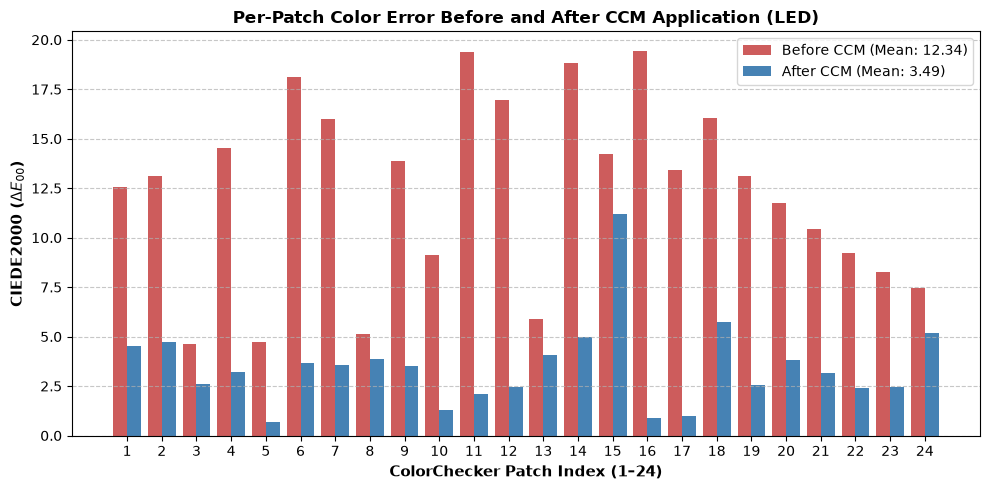

'c:\\Users\\nmmon\\Desktop\\EE513\\Project1\\camera_characterization\\outputs\\figures\\color_delta_e_before_after.png'

In [ ]:
# ---------------------------------------------------------
# 3. Process Color Captures
# ---------------------------------------------------------
# Set flat field configuration with LED white sheet that did not clip
per_patch_errors = {}
summary_results = {}
# Maps standard linear sRGB primaries ([R, G, B]) into CIE 1931 XYZ tristimulus coordinates ([X, Y, Z])
srgb_matrix = color.SRGB_TO_XYZ

if real_color_dir:
    print(f"Processing Real Color Captures from: {real_color_dir}")
    led_cfg = illuminant_config["LED"]
    scene_path = os.path.join(real_color_dir, led_cfg["scene"])
    ws_path = os.path.join(real_color_dir, led_cfg["white"])

    # ------------------------------------------------------------------
    # 1. Linear Quarter-Resolution Bayer Extraction & Vignetting Removal
    # ------------------------------------------------------------------
    scene_rgb = color.extract_quarter_res_linear_rgb(scene_path, black_level=black_level, white_level=white_level)
    ws_rgb = color.extract_quarter_res_linear_rgb(ws_path, black_level=black_level, white_level=white_level)
    scene_corr = color.apply_lens_shading_correction(scene_rgb, ws_rgb)
    
    # -----------------------------------------------------------------------------
    # 2. Inner-50% Patch Sampling, Orientation Alignment & Von Kries White Balance
    # -----------------------------------------------------------------------------
    raw_means = color.extract_colorchecker_manual(scene_corr, grid_bbox=led_cfg["bbox"])
    led_aligned = color.align_patch_means(raw_means)
    gains_led, led_balanced = color.compute_white_balance_gains(led_aligned, neutral_patch_idx=20)
    
    # ---------------------------------------------------------
    # 3. Pre-CCM Baseline & Constrained-Free Least-Squares 3x3 CCM Fit
    # ---------------------------------------------------------    
    baseline_xyz = led_balanced @ srgb_matrix.T
    meas_white_base = baseline_xyz[18]

    mean_de_before, std_de_before, worst_de_before, de_before_list = color.evaluate_delta_e(
        baseline_xyz, color.COLORCHECKER_REF_XYZ, white_ref_xyz=meas_white_base
    )

    CCM = color.fit_color_correction_matrix(led_balanced, color.COLORCHECKER_REF_XYZ)

    # ---------------------------------------------------------
    # 4. Cross-Illuminant Transfer Evaluation (Fixed LED CCM)
    # ---------------------------------------------------------
    for name, cfg in illuminant_config.items():
        sc_p = os.path.join(real_color_dir, cfg["scene"])
        ws_p = os.path.join(real_color_dir, cfg["white"])
        sc_rgb = color.extract_quarter_res_linear_rgb(sc_p, black_level=black_level, white_level=white_level)
        w_rgb = color.extract_quarter_res_linear_rgb(ws_p, black_level=black_level, white_level=white_level)
        sc_c = color.apply_lens_shading_correction(sc_rgb, w_rgb)
        r_means = color.extract_colorchecker_manual(sc_c, grid_bbox=cfg["bbox"])
        alg_means = color.align_patch_means(r_means)
        gns, bal_means = color.compute_white_balance_gains(alg_means, neutral_patch_idx=20)
        
        # Apply the fixed LED CCM unchanged; adapt CIELAB white point to this round's White Patch 19
        corrected_xyz = bal_means @ CCM.T
        #meas_white_xyz = bal_means[18] @ srgb_matrix.T
        
        m_de, s_de, w_de, de_list = color.evaluate_delta_e(
            corrected_xyz, color.COLORCHECKER_REF_XYZ #, white_ref_xyz=meas_white_xyz
        )
        summary_results[name] = {"mean_de": m_de, "std_de": s_de, "worst_de": w_de}
        per_patch_errors[name] = de_list
else:
    print("DNG color captures not found on local disk. Running synthetic multi-illuminant benchmark.")
    ref_xyz = color.COLORCHECKER_REF_XYZ
    sensor_sens = np.array([[2.85, -0.45, 0.10], [-0.35, 1.80, -0.20], [0.05, -0.30, 1.15]])
    illuminant_shifts = {
        "LED":          np.array([0.94, 1.03, 1.12]),
        "Outdoors":     np.array([1.0, 1.0, 1.0]),
        "Overhead":     np.array([1.08, 1.0, 0.92]),
        "Incandescent": np.array([1.28, 0.96, 0.72])
    }
    led_raw = (ref_xyz @ sensor_sens.T) * illuminant_shifts["LED"]
    _, led_balanced = color.compute_white_balance_gains(led_raw, neutral_patch_idx=20)
    baseline_xyz = led_balanced @ srgb_matrix.T
    white_ref_base = baseline_xyz[18]
    mean_de_before, std_de_before, _, de_before_list = color.evaluate_delta_e(
        baseline_xyz, ref_xyz, white_ref_xyz=white_ref_base
    )

    CCM = color.fit_color_correction_matrix(led_balanced, ref_xyz)

    for name, shift in illuminant_shifts.items():
        raw_rgb = (ref_xyz @ sensor_sens.T) * shift
        _, bal_rgb = color.compute_white_balance_gains(raw_rgb, neutral_patch_idx=20)
        corrected_xyz = bal_rgb @ CCM.T
        meas_w = bal_rgb[18] @ srgb_matrix.T
        m_de, s_de, w_de, de_list = color.evaluate_delta_e(corrected_xyz, ref_xyz, white_ref_xyz=meas_w)
        summary_results[name] = {"mean_de": m_de, "std_de": s_de, "worst_de": w_de}
        per_patch_errors[name] = de_list

primary_res = summary_results.get("LED", {"mean_de": 0.0, "std_de": 0.0, "worst_de": 0.0})
color_payload = {
    "de_mean_before": [float(mean_de_before), float(std_de_before)],
    "de_mean_after": [float(primary_res["mean_de"]), float(primary_res["std_de"])],
    "de_worst_after": [float(primary_res["worst_de"]), 0.0],
    "ccm_matrix": CCM.tolist()
}

print("\nFitted 3x3 Color Correction Matrix (CCM):")
print(np.round(CCM, 4))

patch_names = color.get_reference_patch_names()
worst_idx_before = int(np.argmax(de_before_list))
worst_idx_after = int(np.argmax(per_patch_errors["LED"]))

print(f"Mean CIEDE2000 ΔE_00 BEFORE CCM : {mean_de_before:.2f} ± {std_de_before:.2f}")
print(f"Worst Patch  ΔE_00 BEFORE CCM  : {worst_de_before:.2f} ({patch_names[worst_idx_before]})")
print(f"Mean CIEDE2000 ΔE_00 AFTER CCM  : {summary_results['LED']['mean_de']:.2f} ± {summary_results['LED']['std_de']:.2f}")
print(f"Worst Patch  ΔE_00 AFTER CCM   : {summary_results['LED']['worst_de']:.2f} ({patch_names[worst_idx_after]})\n")

plots.plot_color_delta_e_before_after(
    delta_e_before=de_before_list,
    delta_e_after=per_patch_errors["LED"],
    illuminant_name="LED",
    output_dir=output_dir,
)

In [36]:
# #Sanity-check that white-balancing Patch 21 actually moved White Patch 19's CIE (x, y) chromaticity close to the D50 reference white
led_corrected_xyz = led_balanced @ CCM.T

# Compare White Patch 19 (0-indexed 18) chromaticity (x, y) before vs. after CCM
print("Before white xy   :", np.round(colour.XYZ_to_xy(baseline_xyz[18]), 6))
print("After LED white xy:", np.round(colour.XYZ_to_xy(led_corrected_xyz[18]), 6))
print("Ref patch 19 xy   :", np.round(colour.XYZ_to_xy(color.COLORCHECKER_REF_XYZ[18]), 6))

Before white xy   : [ 0.315173  0.33112 ]
After LED white xy: [ 0.35029   0.368455]
Ref patch 19 xy   : [ 0.348914  0.364213]


In [37]:
# ---------------------------------------------------------
# 4. Cosine Similarity Matrix
# ---------------------------------------------------------
ext = color_cfg.get("file_extension", ".dng")
all_color_files = utils.find_target_images(real_color_dir, ext)
led_files = sorted([
    f for f in all_color_files
    if "led" in os.path.basename(f).lower() and "white" not in os.path.basename(f).lower()
])

led_white_path = os.path.join(real_color_dir, "led_white.dng")
ccm_sim_results = color.evaluate_ccm_column_cosine_similarity(
    color_file_paths=led_files,
    bboxes_dict=COLORCHECKER_BBOXES,
    white_sheet_path=led_white_path,
    black_level=black_level,
    white_level=white_level,
    verbose=False,  # Set to False if you only want the Summary Table printed
)


     SUMMARY TABLE: COLUMN-WISE COSINE SIMILARITY        
Comparison Pair              | Col 1 (Red)  | Col 2 (Green) | Col 3 (Blue)
-------------------------------------------------------------------------
led_1.dng vs. led_2.dng      | 0.9976       | 0.9993       | 0.9997      
led_1.dng vs. led_3.dng      | 0.9978       | 0.9993       | 0.9999      
led_2.dng vs. led_3.dng      | 0.9998       | 1.0000       | 0.9999      
----------------------------------------------------------



--- Multi-Illuminant Delta E (CIEDE2000) Performance ---
Illuminant      | Mean Delta E00  | Worst Delta E00
------------------------------------------------
LED             |   3.49 +/- 2.14 |  11.20
Outdoors        |   7.59 +/- 6.67 |  24.26
Overhead        |   4.92 +/- 1.82 |   9.43
Incandescent    |   4.87 +/- 2.88 |  15.58
------------------------------------------------
[PLOT] Saved at: c:\Users\nmmon\Desktop\EE513\Project1\camera_characterization\outputs\figures\color_delta_e_across_illuminants.png


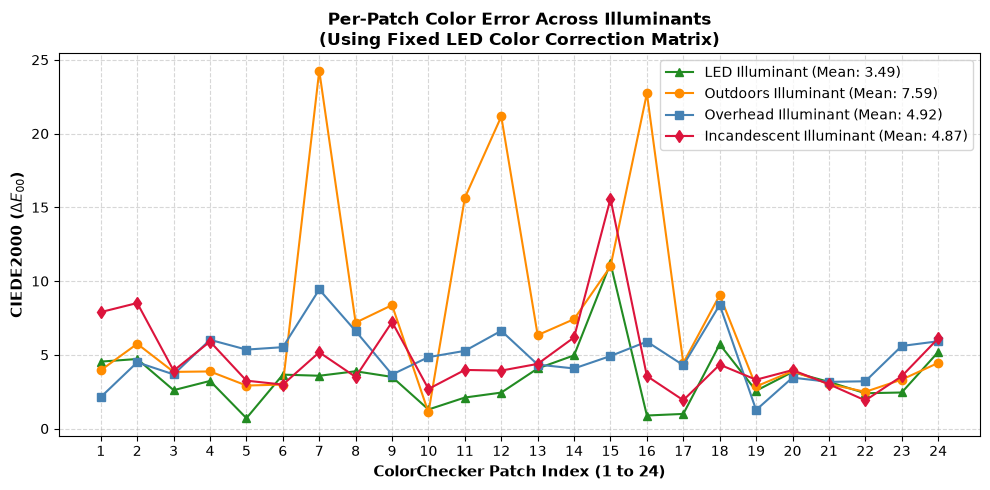

'c:\\Users\\nmmon\\Desktop\\EE513\\Project1\\camera_characterization\\outputs\\figures\\color_delta_e_across_illuminants.png'

In [38]:
# ---------------------------------------------------------
# 5. Multi-Illuminant Delta E (CIEDE2000) Performance
# ---------------------------------------------------------
print("\n--- Multi-Illuminant Delta E (CIEDE2000) Performance ---")
print(f"Illuminant      | Mean Delta E00  | Worst Delta E00")
print("-" * 48)
for name, res in summary_results.items():
    print(f"{name:<15} | {res['mean_de']:6.2f} +/- {res['std_de']:4.2f} | {res['worst_de']:6.2f}")
print("-" * 48)


plots.plot_color_delta_e_across_illuminants(per_patch_errors, output_dir=output_dir)


In [39]:
# ---------------------------------------------------------
# 6. Multi-Chart Calibration
# ---------------------------------------------------------
multi_led = color.evaluate_multi_chart_de(
    color_file_paths=led_files,
    CCM=CCM,
    illuminant_name="LED",
    white_sheet_path=led_white_path,
    bboxes_dict=COLORCHECKER_BBOXES,
    black_level=black_level,
    white_level=white_level,
)
color_payload["de_mean_after"] = multi_led["de_mean_after"]
color_payload["de_worst_after"] = multi_led["de_worst_after"]


--- Per-Capture LED Results (After CCM) ---
led_1.dng      | Mean ΔE_00 = 3.49 | Worst = 11.20 (15. Red)
led_2.dng      | Mean ΔE_00 = 3.61 | Worst = 11.05 (15. Red)
led_3.dng      | Mean ΔE_00 = 3.51 | Worst = 11.30 (15. Red)

--- Summary Across All 3 LED Captures ---
Mean Patch ΔE_00 (3-chart mean ± std) : 3.53 ± 0.06
Worst Patch ΔE_00 (3-chart mean ± std): 11.19 ± 0.13

--- Top 3 Worst Patches (Averaged Across All 3 LED Captures) ---
1. 15. Red                | Mean ΔE_00 = 11.19
2. 18. Cyan               | Mean ΔE_00 = 5.94
3. 24. Black 2 (1.5 D)    | Mean ΔE_00 = 5.31


In [40]:
# ---------------------------------------------------------
# 6. Worst Patch Inspection
# ---------------------------------------------------------
# Run on LED (or swap `led_files` for `out_files`, `oh_files`, or `incan_files`)
importlib.reload(color)
print("------Worst Patch Inspection-------")
led_diag = color.inspect_capture_diagnostics(
    color_file_paths=led_files,
    CCM=CCM,
    white_sheet_path=led_white_path,
    bboxes_dict=COLORCHECKER_BBOXES,
    inspect_indices=[14, 17, 23],
    black_level=black_level,
    white_level=white_level,
)

------Worst Patch Inspection-------

=== led_1.dng | clipped=False (v_sat=1023) | cond(bal)=13.42 | cond(CCM)=4.09 ===
  15. Red                | aligned RGB=[0.1401, 0.0557, 0.0493] | bal RGB=[0.1426, 0.0557, 0.0494] | ΔE_00=11.204
  18. Cyan               | aligned RGB=[0.0395, 0.0773, 0.1241] | bal RGB=[0.0402, 0.0773, 0.1243] | ΔE_00=5.714
  24. Black 2 (1.5 D)    | aligned RGB=[0.0175, 0.0169, 0.0194] | bal RGB=[0.0178, 0.0169, 0.0195] | ΔE_00=5.189

=== led_2.dng | clipped=False (v_sat=1023) | cond(bal)=13.01 | cond(CCM)=4.09 ===
  15. Red                | aligned RGB=[0.1333, 0.0525, 0.0464] | bal RGB=[0.1353, 0.0525, 0.0464] | ΔE_00=11.054
  18. Cyan               | aligned RGB=[0.0377, 0.0738, 0.1199] | bal RGB=[0.0383, 0.0738, 0.1197] | ΔE_00=6.088
  24. Black 2 (1.5 D)    | aligned RGB=[0.0162, 0.0156, 0.0182] | bal RGB=[0.0164, 0.0156, 0.0181] | ΔE_00=5.444

=== led_3.dng | clipped=False (v_sat=1023) | cond(bal)=13.35 | cond(CCM)=4.09 ===
  15. Red                | aligned 

### Section 8: Exporting Deliverable (results.json)

In [41]:
# Ensure noise_payload carries the 54-frame ISO 22 EXIF black level [mean, std]
noise_payload["black_level"] = [float(bl_mean), float(bl_std)]

exif_meta = {
    "lens_model": f"{camera_make} {camera_model}",
    "capture_app": "Open Camera (Camera2 API)",
    "cfa_pattern": cfa_pattern,
    "width": int(raw_width),
    "height": int(raw_height),
    "binned": True,
    "black_level": float(bl_mean),
    "black_level_std": float(bl_std),
}

geom_results = {
    "f_px": [float(mean_focal_length_px), float(mean_focal_length_uncertainty_px)],
    "f_mm": [float(focal_length_mm), 0.1],
    "cx": calib_payload["principal_point_x"],
    "cy": calib_payload["principal_point_y"],
    "k1": calib_payload["radial_distortion_k1"],
    "k2": calib_payload["radial_distortion_k2"],
    "p1": calib_payload["tangential_distortion_p1"],
    "p2": calib_payload["tangential_distortion_p2"],
    "rms": calib_payload["rms_reprojection_error"],
    "n_views": int(calib_payload["n_views"]),
    "sq_mm": [float(sq_size), 0.5],
}

final_results = utils.export_project1_results_json(
    exif_meta=exif_meta,
    geom_results=geom_results,
    res_results=res_payload,
    noise_results=noise_payload,
    color_results=color_payload,
    output_dir=output_dir,
)

report_generator.generate_characterization_report(
    results_payload=final_results,
    output_dir=output_dir,
)

print("Deliverable exported to results.json")


[SUCCESS] Metrics exported cleanly to: ./outputs\results.json
[SUCCESS] Characterization report generated at: ./outputs\characterization_report.md
Deliverable exported to results.json
